# Normal modes benchmark and verification from simulation

Six nominal values of \(q=0.1..0.6\) and the ion numbers \(N=1,3,6,12,24,48\) are tested using the same five-wire trap. Partially we benchmark normal mode calculation time, but mainly -- analyse the normal mode calculation accuracy by comparing them to frequencies, obtained directly from FFT of the oscillating ion crystal trajectories.

Workflow:

1. **Normal modes calculation (Part A)** — Performs numerical calculation of equilibrium ion positions by potential minimization, and compares them to the positions, obtained from the simulation with cooling. Calculates normal modes with 3 models: harmonic approximation, Mathieu-harmonic and Mathieu anharmonic modes. Supplied equilibrium positions can be chosen: from simulaiton or analytics. 
2. **Simulation of ion crystals (Part B)** — Performs simulation of each of 36 ion crystal configurations (in parallel). Ions are generated with small shift from equilibrium positions, without cooling, to get frequency peaks from Fourier transform of ion trajectories. 
3. **Verification results (Part C)** — Results of the normal mode verifications. Calculates FFT of the ion trajectories, then tries to find the matching FT peaks with calculated modes. 

**Verification limitation:** The calculated Mathieu mode frequencies are used to guide spectral peak detection. This may bias the resulting mode RMSE in favor to calculated modes. It is made for automation of data collection. For specific linear configurations it was tested, that modes can be well resolved by principle oscillation axis, and are close to the calculated values. Each result can be indivually evaluated from provided data. 

**Data preservation:** input benchmark `*.npz` files, trajectories are collected to the supplementary directory under the runname. Set `DATA_DIRECTORY_OVERRIDE` in the initialization cell when opening the notebook from another directory.

In [23]:
from __future__ import division
from pathlib import Path
# For several simultaneous notebook kernels, avoid 6 x many BLAS workers.
# Restart each kernel before running this cell for these defaults to take effect.
import os
for _thread_var in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS',
                    'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ[_thread_var] = '1'  # one BLAS/OpenMP worker per notebook process
import hashlib
import inspect
import json
import os
import platform
import sys
import time
import tempfile
import shutil
from datetime import datetime, timezone
from contextlib import contextmanager

import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import scipy.constants as ct
from scipy.signal import find_peaks
from scipy.optimize import linear_sum_assignment

import sion as sn
import sion.pylion as pl
from sion.electrode import shaped

# Set an ABSOLUTE path here if the notebook is launched from a different folder.
# Point to the folder that already contains modes_benchmark_results/.
# Example: DATA_DIRECTORY_OVERRIDE = Path(r'C:\research\supplementary\mode_verification_and_benchmark')
DATA_DIRECTORY_OVERRIDE = None

def _find_data_directory(override=None):
    if override is not None:
        target = Path(override).expanduser().resolve()
        if not (target / 'modes_benchmark_results').is_dir():
            print(f'No saved results at {target}; initializing a new data directory.')
        return target
    cwd = Path.cwd().resolve()
    candidates = []
    for parent in (cwd, *list(cwd.parents)[:5]):
        candidates.extend((parent,
                           parent / 'mode_verification_and_benchmark',
                           parent / 'supplementary' / 'mode_verification_and_benchmark'))
    candidates = list(dict.fromkeys(candidates))
    ranked = []
    for folder in candidates:
        saved = folder / 'modes_benchmark_results'
        if not saved.is_dir():
            continue
        count = sum(1 for _ in saved.glob('q*_N*.npz'))
        count += sum(1 for _ in saved.glob('q*_N*_trajectory.json'))
        ranked.append((count, folder))
    if ranked:
        highest = max(count for count, _ in ranked)
        winners = [folder for count, folder in ranked if count == highest]
        if len(winners) != 1:
            raise RuntimeError('Multiple possible data directories found: '                               + '\n'.join(map(str, winners))
                               + '\nSet DATA_DIRECTORY_OVERRIDE explicitly.')
        return winners[0]
    # First-run default (does not claim existing results are found).
    return cwd / 'supplementary' / 'mode_verification_and_benchmark'

output_dir = _find_data_directory(DATA_DIRECTORY_OVERRIDE)
results_dir = output_dir / 'modes_benchmark_results'
fft_cache_dir = results_dir / 'fft_cache'
for directory in (output_dir, results_dir, fft_cache_dir):
    directory.mkdir(parents=True, exist_ok=True)
print('Mode benchmark data directory:', output_dir)
print('Saved benchmark files:', len(list(results_dir.glob('q*_N*.npz'))))


ION_MASS_AMU = 40.0  
ION_CHARGE_E = 1

# Run independent external LAMMPS simulations in separate Python processes.
# joblib/loky supports notebook-defined functions on Windows (pip install joblib).
def _isolated_md_job(function, q, N, kwargs):
    old_cwd = Path.cwd()
    work_root = output_dir / 'md_worker_scratch'
    work_root.mkdir(parents=True, exist_ok=True)
    work = Path(tempfile.mkdtemp(prefix=f'{case_name(q,N)}_', dir=work_root))
    success = False
    try:
        os.chdir(work)  # isolate any fixed-name LAMMPS/pyLIon temporary files
        function(q, N, **kwargs)
        success = True
        return None
    except Exception as exc:
        return {'q':float(q),'N':int(N),'error':repr(exc),'scratch':str(work)}
    finally:
        os.chdir(old_cwd)
        if success:
            shutil.rmtree(work, ignore_errors=True)

def _run_md_jobs(function, cases, kwargs, workers=1, stop_on_error=False):
    cases = list(cases)
    if not cases: return []
    if int(workers) != workers or workers < 1:
        raise ValueError('workers must be a positive integer')
    workers = min(int(workers), len(cases))
    settings = kwargs.get('settings', {})
    if workers > 1 and (settings.get('mpi_processes',1) != 1 or settings.get('omp_threads',1) != 1):
        raise ValueError('Parallel cases require mpi_processes=omp_threads=1')
    if workers == 1:
        failures=[]
        for q,N in cases:
            failure=_isolated_md_job(function,q,N,kwargs)
            if failure:
                failures.append(failure)
                if stop_on_error: raise RuntimeError(failure)
        return failures
    try:
        from joblib import Parallel, delayed, parallel_config
    except ImportError as exc:
        raise ImportError('Install joblib for parallel MD runs: pip install joblib') from exc
    # Process isolation, not notebook threads. Each external job uses one core.
    # A parallel batch finishes before returning its failures.
    with parallel_config(backend='loky', inner_max_num_threads=1):
        records=Parallel(n_jobs=workers, batch_size=1, pre_dispatch=workers, verbose=5)(
            delayed(_isolated_md_job)(function,q,N,kwargs) for q,N in cases)
    failures=[r for r in records if r is not None]
    if failures and stop_on_error: raise RuntimeError(failures)
    return failures


Mode benchmark data directory: C:\Users\User\Desktop\ARTEM\Sion\tests\supplementary\mode_verification_and_benchmark
Saved benchmark files: 36


## Trap geometry

Trap geometry was chosen for stable confinement of as many as 48 ions with low RF.

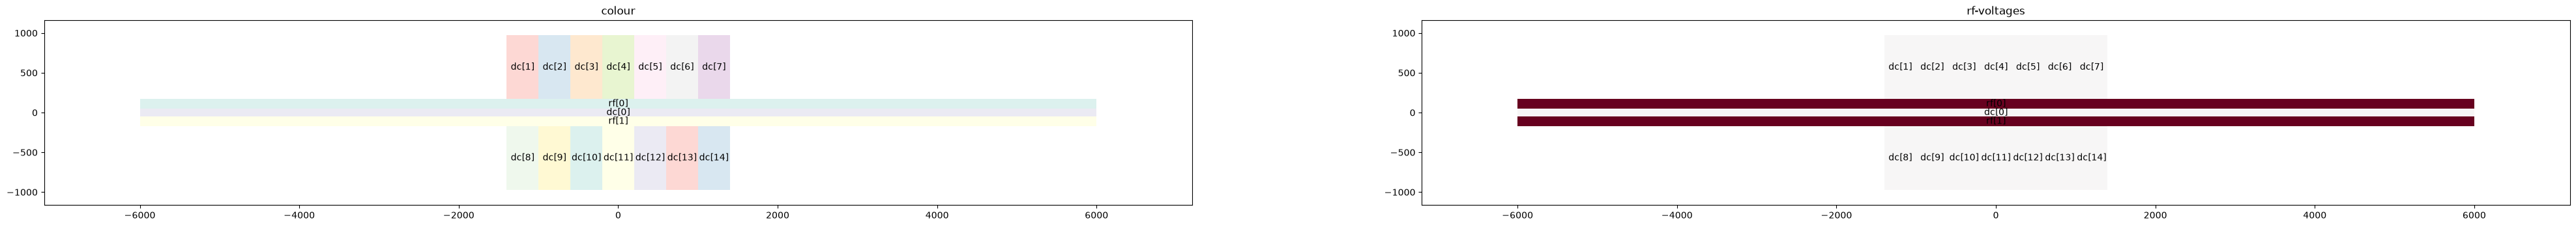

In [24]:
# define trap with large anharmonicity 
L = 1e-6 # length scale
Vrf = 200. # RF peak voltage in V
mass = 40*ct.atomic_mass # ion mass
Z = 1*ct.elementary_charge # ion charge
Omega = 2*np.pi*50e6 # RF frequency in rad/s
Urf = Vrf * np.sqrt(Z / mass) / (2 * L * Omega)
scale = Z / ((L * Omega) ** 2 * mass)

# parameters of trap
top_dc = [[400, 800]]*7  # Array of lengths and widths of Top electrodes
bottom_dc = top_dc  # Array of lengths and widths of Bottom electrodes
central_dc = [12000,100]
gap = 0  # width of gaps between electrodes
top_rf = [12000,120]
bottom_rf = [12000,120]

s, RF_electrodes, DC_electrodes = sn.five_wire_trap_design(Urf, top_dc, bottom_dc, top_rf, bottom_rf, central_dc, 
                                                              gap=gap, need_coordinates = True, need_plot = True,
                                                              figsize=[50,20])

# Part A. Normal modes calculation

The benchmark execution cell is deliberately commented out to avoid repeating expensive work.

Calculates equilibirium ion positions from provided trap configuration. Simulated equilibrium positions search is parallelized. For the calculated equilibrium positions (may be chosen from analytics or MD), obtaines normal modes by 3 models: harmonic, Mathieu with harmonic trap potential, Mathieu with anharmonic trap potential.

Benchmarks the normal mode calculation times. Provides verification by comparing simulated and analytical equilibrium positions. 

## Trap configurations

This code was used to manually obtain configurations for confinement of linear 48 ion chain for various values of q. Currently commented out. 

In [25]:
def manual_trap_config(Vrf, start_dc_set):
    Urf = Vrf * np.sqrt(Z / mass) / (2 * L * Omega)

    s = sn.five_wire_trap_design(Urf, top_dc, bottom_dc, top_rf, bottom_rf, central_dc, 
                                need_coordinates = False, need_plot = False)

    x0 = np.array(s.minimum((0., 0, 30), axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG"))
    rf_set = [Vrf, Vrf]
    dc_set = sn.position_optimization(s, [[x0[0], x0[1], x0[2]]], start_dc_set, eps=1e-2, tol=1e-36,
                                        ion_masses=mass, charges=1, callback_num=500,
                                        voltage_bounds=(np.min(start_dc_set)*1.2, np.max(start_dc_set)*1.2))

    u_set = np.concatenate((np.zeros(2), dc_set))

    with s.with_voltages(dcs = u_set, rfs = None):
        x1 = np.array(s.minimum(x0*1.001, axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG"))
        distance = np.round((x1-x0), 5)
        omega_sec, mod_dir = sn.single_ion_modes(s, x1, mass)
        alpha = (omega_sec[0]/omega_sec[1])**2
        N_cr = (alpha / 2.53)**(-1/1.73)

    with s.with_voltages(dcs = u_set, rfs = rf_set):
        params = sn.stability(s, mass, Omega, minimum = x1, need_plot=False) 

    q = params['Ion (M = 40, Z = 1)']['q'].real

    return distance, omega_sec, N_cr, q, dc_set

# #for manual configuration choice
# Vrf = 358
# dc_set = 0.36*np.array([-4.04, 10, 4, -4, -10, -4, 4, 10, 10, 4, -4, -10, -4, 4, 10]) 

# distance, omega_sec, N_cr, q, dc_set = manual_trap_config(Vrf, dc_set)

# print(f'Distance = {distance}')
# print(f'omega_sec = {np.round(omega_sec*1e-3, 3)} kHz')
# print(f'Critical ion number: {N_cr}')
# print(f'q = {np.round(q,3)}')
# print([float(f) for f in dc_set], ',')

## Configuration functions

Configures benchmark and normal mode calculation.

In [26]:
configurations = {
    "qs": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6],
    "ion_numbers": [1,3,6,12,24,48],
    "Vrfs": [59.5, 119.5, 179, 239, 298.5, 358],
    "dc_sets": [[-0.039683576580273466, 0.09979342924589318, 0.03946219730780732, -0.04035739538254305, -0.1000894258545118, -0.04035739538254304, 0.03946219730780732, 0.09979342924589318, 0.09979342924591406, 0.039462197307912804, -0.04035739538150908, -0.10008942584901877, -0.04035739538150908, 0.039462197307912804, 0.09979342924591406],
                [-0.1583209555588639, 0.39994192180112187, 0.15984879442471978, -0.16054414894935604, -0.4004089608419386, -0.16054414894935604, 0.15984879442471978, 0.39994192180112187, 0.39994192180112187, 0.15984879442471978, -0.16054414894935604, -0.4004089608419386, -0.16054414894935604, 0.15984879442471978, 0.39994192180112187] ,
                [-0.3561318875239949, 0.8999435054008814, 0.3598529141366885, -0.36052936982392325, -0.901283312243702, -0.3605293698239256, 0.3598529141366897, 0.8999435054008814, 0.8999435054008814, 0.3598529141366897, -0.3605293698239245, -0.9012833122436951, -0.36052936982392214, 0.3598529141366897, 0.8999435054008814] ,
                [-0.6327118648576588, 1.5998965635998386, 0.6397307116992303, -0.6409690866882003, -1.602348483979161, -0.6409690866882003, 0.6397307116992303, 1.5998965635998386, 1.5998965635998386, 0.6397307116992187, -0.640969086688212, -1.6023484839792097, -0.640969086688212, 0.6397307116992187, 1.5998965635998386] ,
                [-0.9886043371031225, 2.499833660846135, 0.9995936354237385, -1.001511873353476, -2.50365024797245, -1.0015118733612152, 0.9995936483675094, 2.4998336608457508, 2.499833660846227, 0.9995936354241769, -1.0015118733492132, -2.5036502479449596, -1.0015118733569561, 0.9995936354228127, 2.4998336608458342] ,
                [-1.4238277794696914, 3.5996600285224445, 1.4393554289238244, -1.4421264208798616, -3.6052094180549497, -1.442126416232109, 1.4393554316730952, 3.5996600299202375, 3.599660040498397, 1.4393557346172632, -1.4421267669318834, -3.6052092950806784, -1.4421267726406783, 1.4393557350461132, 3.599660040561283] 
                ],
}

BENCHMARK_SETTINGS = {
    'equilibrium_md_steps': 250_000,
    'equilibrium_dump_steps': 20,
    'equilibrium_average_frames': 1000,
    'langevin_damping': 1e-7,
    'equilibrium_start_spacing_m': 7e-6,
    'linearity_tolerance_um': 1,
    'timing_repeats': 1,   
    'analytic_epsilon': 1e-8, 
    'analytic_tol': 1e-8,     
    'mpi_processes': 1,
    'omp_threads': 1,
}


def q_label(q):
    """Canonical, stable filename token; not an index derived from q*10."""
    return f'{float(q):.3f}'.replace('.', 'p')


def case_name(q, ion_number):
    return f'q{q_label(q)}_N{int(ion_number):03d}'


def case_path(q, ion_number):
    return results_dir / f'{case_name(q, ion_number)}.npz'


def configuration_for_q(q, configs=None):
    if configs is None:
        configs = configurations
    qs = np.asarray(configs['qs'], dtype=float)
    ids = np.flatnonzero(np.isclose(qs, float(q), atol=1e-10, rtol=0))
    if len(ids) != 1:
        raise ValueError(f'Unknown or ambiguous nominal q={q}; configured: {qs}')
    j = int(ids[0])
    return float(configs['Vrfs'][j]), np.asarray(configs['dc_sets'][j], dtype=float)


def is_linear_crystal(positions_um, tolerance=0.3):
    """Maximum transverse distance from the mean (y,z) position, in µm."""
    p = np.asarray(positions_um, dtype=float)
    if p.ndim != 2 or p.shape[1] != 3 or not np.all(np.isfinite(p)):
        raise ValueError('positions_um must be a finite array of shape (N, 3)')
    if tolerance < 0:
        raise ValueError('tolerance must be nonnegative')
    deviations = np.linalg.norm(p[:, 1:] - p[:, 1:].mean(axis=0), axis=1)
    return deviations, bool(np.max(deviations) <= tolerance)


def equilibrium_metrics(analytic_um, md_um, tolerance_um=0.3):
    """Match ions by axial order and compare absolute equilibrium coordinates."""
    a = np.asarray(analytic_um, dtype=float)
    d = np.asarray(md_um, dtype=float)
    if a.shape != d.shape or a.ndim != 2 or a.shape[1] != 3:
        raise ValueError('Both arrays must have shape (N, 3)')
    a, d = a[np.argsort(a[:, 0])], d[np.argsort(d[:, 0])]
    displacement = d - a
    error_per_ion = np.linalg.norm(displacement, axis=1)
    av, al = is_linear_crystal(a, tolerance_um)
    dv, dl = is_linear_crystal(d, tolerance_um)
    return {
        'rms_position_error_um': float(np.sqrt(np.mean(error_per_ion**2))),
        'max_position_error_um': float(np.max(error_per_ion)),
        'center_offset_um': displacement.mean(axis=0).tolist(),
        'max_transverse_analytic_um': float(np.max(av)),
        'max_transverse_md_um': float(np.max(dv)),
        'analytic_is_linear': bool(al),
        'md_is_linear': bool(dl),
    }


def _system_rf_coefficients(rf_voltages_v):
    """Convert the physical RF voltage (V) to the normalized electrode.System RF coefficient.
    """
    return np.asarray(rf_voltages_v, dtype=float) * np.sqrt(Z/mass) / (2*L*Omega)


def make_system(q, configs=None):
    Vrf, dc_set = configuration_for_q(q, configs)
    Urf = Vrf * np.sqrt(Z / mass) / (2 * L * Omega)
    system = sn.five_wire_trap_design(
        Urf, top_dc, bottom_dc, top_rf, bottom_rf, central_dc,
        gap=gap, need_coordinates=False, need_plot=False
    )
    rf_set = [Vrf, Vrf]
    full_dcs = np.concatenate((np.zeros(2), dc_set))
    x0_um = np.asarray(system.minimum(
        (0., 0., 30.), axis=(0, 1, 2), coord=np.eye(3), method='Newton-CG'
    ), dtype=float)
    with system.with_voltages(dcs=full_dcs, rfs=None):
        x1_um = np.asarray(system.minimum(
            x0_um*1.001, axis=(0, 1, 2), coord=np.eye(3), method='Newton-CG'
        ), dtype=float)
        single_hz, _ = sn.single_ion_modes(system, x1_um, mass, L=L)
    return system, x0_um, x1_um, np.asarray(single_hz, dtype=float), dc_set, rf_set, full_dcs


def _single_ion_theory_from_system(system, position_um, full_dcs, rf_set):
    normalized_rf = _system_rf_coefficients(rf_set)
    with system.with_voltages(dcs=full_dcs, rfs=None):
        harmonic_hz, harmonic_vectors = sn.single_ion_modes(
            system, np.asarray(position_um, float), mass, L=L)
    with system.with_voltages(dcs=full_dcs, rfs=normalized_rf):
        mathieu_hz, mathieu_vectors = sn.single_ion_modes(
            system, np.asarray(position_um, float), mass,
            L=L, mathieu=True, Omega=Omega)
    return (np.asarray(harmonic_hz, float), np.asarray(harmonic_vectors),
            np.asarray(mathieu_hz, float), np.asarray(mathieu_vectors))


def check_linearity(configs=None, tolerance_um=0.1):
    """Manual preflight for largest ion crystal of each q; does not persist data."""
    if configs is None:
        configs = configurations
    N = max(configs['ion_numbers'])
    for q in configs['qs']:
        system, x0, _, _, dc_set, _, _ = make_system(q, configs)
        pos_um = np.asarray(sn.equilibrium_ion_positions(
            system, dc_set, mass, N, potential_minimum=x0, L=L
        ), dtype=float)
        deviations, linear = is_linear_crystal(pos_um, tolerance=tolerance_um)
        print(f'q={q:g}, N={N}, linear={linear}, '
              f'max transverse deviation={np.max(deviations):.6g} µm')


def equilibrium_positions_from_simulation(q, ion_number, x1_um, dc_set, rf_set,
                                          settings=BENCHMARK_SETTINGS):
    """Independent damped MD equilibrium; return sorted equilibrium coordinates in µm.
    """
    key = case_name(q, ion_number)
    dump_file = output_dir / f'equilibrium_{key}.lammpstrj'
    si = pl.Simulation(str(output_dir / f'equilibrium_{key}'))
    starts_m = np.asarray(sn.ions_in_order(
        np.asarray(x1_um, dtype=float) * L, int(ion_number),
        settings['equilibrium_start_spacing_m']
    ), dtype=float)
    si.append(pl.placeions({'mass': ION_MASS_AMU, 'charge': ION_CHARGE_E}, starts_m))
    si.append(sn.polygon_trap([Omega, Omega], rf_set, dc_set,
                              RF_electrodes, DC_electrodes))
    si.append(pl.langevinbath(0, settings['langevin_damping']))
    si.append(pl.dump(str(dump_file), variables=['x', 'y', 'z'],
                      steps=settings['equilibrium_dump_steps']))
    si.append(pl.evolve(settings['equilibrium_md_steps']))
    si.execute(mpi_processes=settings['mpi_processes'],
               omp_threads=settings['omp_threads'])
    _, data_m = pl.readdump(str(dump_file))
    data_m = np.asarray(data_m, dtype=float)
    if int(ion_number) == 1 and data_m.ndim == 2 and data_m.shape[1] == 3:
        data_m = data_m[:, None, :]
    if data_m.ndim != 3 or data_m.shape[1:] != (ion_number, 3):
        raise ValueError(f'Unexpected equilibrium MD dump shape {data_m.shape}')
    tail = int(settings['equilibrium_average_frames'])
    if len(data_m) < tail:
        raise ValueError(f'Equilibrium MD needs >= {tail} dumped frames; got {len(data_m)}')
    mean_positions_um = data_m[-tail:].mean(axis=0) / L
    return mean_positions_um[np.argsort(mean_positions_um[:, 0])]


def timed_call(func, repeats=1):
    """Return call result plus individual wall times."""
    if repeats < 1:
        raise ValueError('repeats must be >=1')
    times, result = [], None
    for _ in range(repeats):
        start = time.perf_counter()
        result = func()
        times.append(time.perf_counter() - start)
    return result, times


def _checked_frequencies(value, n_expected, label):
    f = np.asarray(value, dtype=float).ravel()
    if f.size != n_expected or not np.all(np.isfinite(f)):
        raise ValueError(f'{label} returned invalid frequencies: shape={f.shape}')
    return f


def benchmark_signature(q, settings, configs=None):
    Vrf, dcs = configuration_for_q(q, configs)
    definition = {
        'vrf': Vrf, 'dc_set': dcs.tolist(),
        'top_dc': top_dc, 'bottom_dc': bottom_dc,
        'top_rf': top_rf, 'bottom_rf': bottom_rf, 'central_dc': central_dc,
        'gap': gap, 'Omega': float(Omega), 'L': float(L),
        'mass': float(mass), 'settings': dict(settings),
    }
    encoded = json.dumps(definition, sort_keys=True).encode('utf-8')
    return hashlib.sha256(encoded).hexdigest()

def save_case(q, N, arrays, metadata):
    """Atomic per-case save: only a completed file counts as a finished case."""
    path = case_path(q, N)
    tmp = path.with_suffix('.partial.npz')
    with tmp.open('wb') as fd:
        np.savez_compressed(fd, **arrays,
                            metadata_json=np.array(json.dumps(metadata, allow_nan=False)))
    os.replace(tmp, path)
    return path


def load_case(q, N):
    path = case_path(q, N)
    if not path.exists():
        raise FileNotFoundError(f'Missing benchmark: {path}. Run run_benchmark() first.')
    with np.load(path, allow_pickle=False) as saved:
        arrays = {k: saved[k] for k in saved.files if k != 'metadata_json'}
        metadata = json.loads(str(saved['metadata_json'].item()))
    return arrays, metadata


def normal_mode_benchmark(q, ion_number, settings=BENCHMARK_SETTINGS, configs=None, md_um=None):
    """Calculate and time independent methods and equilibrium sources for one case.
    """
    N = int(ion_number)
    system, x0_um, x1_um, single_hz, dc_set, rf_set, full_dcs = make_system(q, configs)
    meta = {
        'nominal_q': float(q), 'ion_number': N, 'rf_voltages_v': rf_set,
        'dc_voltages_v': dc_set.tolist(), 'rf_angular_frequency_rad_s': float(Omega),
        'L_m': float(L), 'mass_kg': float(mass),
        'settings': dict(settings), 'created_utc': datetime.now(timezone.utc).isoformat(),
        'python': sys.version.split()[0], 'platform': platform.platform(),
        'unit_convention': 'positions_um for equilibria; positions_m for modes; frequencies_hz',
        'times_s': {}, 'position_comparison': None,
        'config_signature': benchmark_signature(q, settings, configs),
    }
    arrays = {
        'rf_minimum_um': x0_um,
        'dc_minimum_um': x1_um,
        'single_ion_secular_hz': single_hz,
    }

    if N == 1:
        arrays['positions_analytic_um'] = x1_um[None, :]
        harmonic_hz, harmonic_vectors, mathieu_hz, mathieu_vectors = (
            _single_ion_theory_from_system(system, x1_um, full_dcs, rf_set))
        arrays['single_ion_secular_hz'] = _checked_frequencies(
            harmonic_hz, 3, 'single-ion harmonic')
        arrays['single_ion_mathieu_hz'] = _checked_frequencies(
            mathieu_hz, 3, 'single-ion Mathieu')
        arrays['freq_analytic_harmonic_hz'] = arrays['single_ion_secular_hz']
        arrays['freq_analytic_single_ion_mathieu_hz'] = arrays['single_ion_mathieu_hz']
        arrays['modes_analytic_harmonic'] = harmonic_vectors
        arrays['modes_analytic_single_ion_mathieu'] = mathieu_vectors
        meta['single_ion_rf_units'] = 'normalized electrode.System coefficients'
        meta['note'] = ('N=1: correctly RF-normalized single-ion Mathieu control; '
                        'no multi-ion timing comparison.')
        return arrays, meta

    eq_kwargs = {'potential_minimum': x0_um, 'L': L}
    supported = inspect.signature(sn.equilibrium_ion_positions).parameters
    if 'epsilon' in supported:
        eq_kwargs['epsilon'] = settings['analytic_epsilon']
    if 'tol' in supported:
        eq_kwargs['tol'] = settings['analytic_tol']
    meta['equilibrium_solver_kwargs'] = {k: (v.tolist() if isinstance(v,np.ndarray) else v)
                                          for k,v in eq_kwargs.items()}
    (analytic_um, pos_times) = timed_call(
        lambda: sn.equilibrium_ion_positions(
            system, dc_set, mass, N, **eq_kwargs),
        settings['timing_repeats']
    )
    analytic_um = np.asarray(analytic_um, dtype=float)
    analytic_um = analytic_um[np.argsort(analytic_um[:, 0])]
    arrays['positions_analytic_um'] = analytic_um
    meta['times_s']['equilibrium_analytic'] = pos_times

    if md_um is None:
        md_um = equilibrium_positions_from_simulation(q,N,x1_um,dc_set,rf_set,settings)
    md_um=np.asarray(md_um,float)
    if md_um.shape != (N,3) or not np.all(np.isfinite(md_um)):
        raise ValueError('Invalid MD equilibrium data')
    arrays['positions_md_um'] = md_um
    meta['position_comparison'] = equilibrium_metrics(
        analytic_um, md_um, settings['linearity_tolerance_um'])

    omega_per_ion = np.tile(single_hz, (N, 1))
    for source, positions_um in [('analytic', analytic_um), ('md', md_um)]:
        positions_m = positions_um * L  # IMPORTANT: both mode solvers require SI metres
        models = {
            'harmonic': lambda positions_m=positions_m: sn.normal_modes(
                positions_m, omega_per_ion, mass, reshape=True),
            'mathieu_harmonic': lambda positions_m=positions_m: sn.crystal_modes(
                positions_m, mass, system, rf_set, Omega, dc_set,
                L=L, reshape=True, anharmonic=False),
            'mathieu_anharmonic': lambda positions_m=positions_m: sn.crystal_modes(
                positions_m, mass, system, rf_set, Omega, dc_set,
                L=L, reshape=True, anharmonic=True),
        }
        for model_name, compute in models.items():
            (result, times) = timed_call(compute, settings['timing_repeats'])
            freqs, vectors = result
            name = f'{source}_{model_name}'
            arrays[f'freq_{name}_hz'] = _checked_frequencies(freqs, 3*N, name)
            arrays[f'modes_{name}'] = np.asarray(vectors)
            meta['times_s'][name] = times
    return arrays, meta


def _md_equilibrium_cache_path(q,N):
    folder=results_dir/'equilibrium_precomputed'
    folder.mkdir(parents=True,exist_ok=True)
    return folder/f'{case_name(q,N)}.npz'

def _read_precomputed_equilibrium(q,N,settings,configs):
    path=_md_equilibrium_cache_path(q,N)
    if not path.exists():return None
    with np.load(path,allow_pickle=False) as fd:
        if str(fd['signature'].item()) != benchmark_signature(q,settings,configs):return None
        pos=np.asarray(fd['positions_um'],float)
    if pos.shape!=(N,3) or not np.all(np.isfinite(pos)):raise ValueError(f'Invalid {path}')
    return pos

def _prepare_one_equilibrium(q,N,settings,configs,reuse=True):
    path=_md_equilibrium_cache_path(q,N)
    lock=path.with_suffix('.lock')
    fd=os.open(str(lock),os.O_CREAT|os.O_EXCL|os.O_WRONLY)
    os.close(fd)
    try:
        if reuse and _read_precomputed_equilibrium(q,N,settings,configs) is not None:return
        _,_,x1,_,dc,rf,_=make_system(q,configs)
        pos=equilibrium_positions_from_simulation(q,N,x1,dc,rf,settings)
        tmp=path.with_suffix('.partial.npz')
        np.savez_compressed(tmp,positions_um=pos,signature=np.array(benchmark_signature(q,settings,configs)))
        os.replace(tmp,path)
    finally:
        lock.unlink(missing_ok=True)

def run_benchmark(configs=configurations, settings=BENCHMARK_SETTINGS,
                  resume=True, stop_on_error=False, limit_cases=None, md_workers=36):
    """Precompute untimed MD equilibria in parallel; run all timed solvers serially.

    No timed solver overlaps an MD worker started by this function. Do not run
    unrelated simulations or other benchmark kernels during the timing stage.
    """
    cases=selected_cases(configs)
    if limit_cases is not None:cases=cases[:int(limit_cases)]
    pending=[]
    for q,N in cases:
        path=case_path(q,N)
        if resume and path.exists():
            _,meta=load_case(q,N)
            if meta.get('config_signature') != benchmark_signature(q,settings,configs):
                raise ValueError(f'Existing {path.name} differs from requested settings; use resume=False explicitly.')
            if N==1 and meta.get('single_ion_rf_units') != 'normalized electrode.System coefficients':
                raise ValueError(f'Outdated N=1 file {path}; regenerate with resume=False.')
            print(f'SKIP {case_name(q,N)} (saved)')
        else:pending.append((q,N))
    failures=_run_md_jobs(_prepare_one_equilibrium,[(q,N) for q,N in pending if N>1],
        dict(settings=settings,configs=configs,reuse=resume),workers=md_workers,stop_on_error=stop_on_error)
    failed={(r['q'],r['N']) for r in failures}
    for q,N in pending:
        if (q,N) in failed:continue
        try:
            pos=_read_precomputed_equilibrium(q,N,settings,configs) if N>1 else None
            if N>1 and pos is None:raise RuntimeError('MD precomputation missing')
            print(f'RUN serial timed solvers {case_name(q,N)}',flush=True)
            arrays,meta=normal_mode_benchmark(q,N,settings=settings,configs=configs,md_um=pos)
            print('  saved',save_case(q,N,arrays,meta).name,flush=True)
        except Exception as exc:
            failures.append({'q':q,'N':N,'error':repr(exc)})
            if stop_on_error:raise
    (results_dir/'benchmark_failures.json').write_text(json.dumps(failures,indent=2),encoding='utf-8')
    return failures


def selected_cases(configs=configurations, q_values=None, ion_numbers=None,
                   case_pairs=None):
    """Validate and enumerate only requested (q, N) configurations.

    `q_values` and `ion_numbers` form a Cartesian subset of the stored grid.
    For an arbitrary subset, pass `case_pairs=[(0.1, 1), (0.3, 6)]` instead.
    """
    if case_pairs is not None:
        if q_values is not None or ion_numbers is not None:
            raise ValueError('Use case_pairs OR q_values/ion_numbers, not both')
        raw = list(case_pairs)
    else:
        qs = list(configs['qs'] if q_values is None else q_values)
        ns = list(configs['ion_numbers'] if ion_numbers is None else ion_numbers)
        raw = [(q, N) for q in qs for N in ns]
    allowed_n = set(int(n) for n in configs['ion_numbers'])
    out, seen = [], set()
    for q, N in raw:
        # q must be part of the existing trap configuration table.
        configuration_for_q(q, configs)
        if isinstance(N, (bool, np.bool_)) or int(N) != N or int(N) not in allowed_n:
            raise ValueError(f'Unsupported N={N}; available: {sorted(allowed_n)}')
        q_config = next(float(x) for x in configs['qs']
                        if np.isclose(float(x), float(q), rtol=0, atol=1e-10))
        key = (q_config, int(N))
        if key not in seen:
            out.append(key)
            seen.add(key)
    return out

## Benchmark run

**Long run WARNING: took XX hours for me**

In [27]:
# PREVIEW: expected benchmark jobs and their saved state
jobs = [(q, N) for q in configurations['qs'] for N in configurations['ion_numbers']]
print(f'{len(jobs)} configurations, {sum(case_path(q,N).exists() for q,N in jobs)} already saved')

# Untimed MD relaxation uses separate processes; timed solvers run serially.
MD_EQUILIBRIUM_WORKERS = 36
# Run the full benchmark (uncomment when ready):
# failures = run_benchmark(configurations, resume=True, stop_on_error=False, md_workers=MD_EQUILIBRIUM_WORKERS)

36 configurations, 36 already saved


## Numerical benchmark tables

Results of the benchmark.

In [43]:
def benchmark_tables(configs=configurations, save_csv=True):
    time_rows, eq_rows = [], []
    for q in configs['qs']:
        for N in configs['ion_numbers']:
            if not case_path(q, N).exists():
                continue
            _, metadata = load_case(q, N)
            eq_row = {'q': q, 'N': N, **(metadata.get('position_comparison') or {})}
            eq_rows.append(eq_row)
            for task, samples in metadata['times_s'].items():
                if task == 'equilibrium_md_total': continue  # historical untimed reference data
                for trial, seconds in enumerate(samples):
                    time_rows.append({'q': q, 'N': N, 'task': task,
                                      'trial': trial, 'wall_time_s': float(seconds)})
    times = pd.DataFrame(time_rows, columns=['q', 'N', 'task', 'trial', 'wall_time_s'])
    eq = pd.DataFrame(eq_rows)
    if save_csv:
        times.to_csv(results_dir / 'timings.csv', index=False)
        eq.to_csv(results_dir / 'equilibrium_comparison.csv', index=False)
    return times, eq


def plot_runtime_heatmap(times, task, ax=None):
    """Plot available runtime observations; cells without completed data stay blank."""
    if times.empty:
        raise ValueError('No benchmark files have been saved yet')
    selected = times[times.task == task]
    if selected.empty:
        raise ValueError(f'No timing data for {task!r}')
    pivot = selected.groupby(['N','q'])['wall_time_s'].median().unstack('q')
    if ax is None:
        _, ax = plt.subplots(figsize=(6,4))
    from matplotlib.colors import LogNorm
    values = np.ma.masked_invalid(pivot.to_numpy(dtype=float))
    values = np.ma.masked_less_equal(values, 0)
    if values.count() == 0: raise ValueError('No positive runtimes')
    lo, hi = float(values.min()), float(values.max())
    if lo == hi: lo, hi = lo/1.1, hi*1.1
    image = ax.imshow(values, origin='lower', aspect='auto', norm=LogNorm(vmin=lo,vmax=hi))
    ax.set_xticks(range(len(pivot.columns)), [f'{q:g}' for q in pivot.columns], fontsize = 16)
    ax.set_yticks(range(len(pivot.index)), [str(N) for N in pivot.index], fontsize = 16)
    ax.set_xlabel('$q$', fontsize = 18)
    ax.set_ylabel('$N_I$, ion number', fontsize = 18)
    ax.set_title(f'Mode optimization wall time (s)', fontsize = 18)
    from matplotlib.ticker import LogLocator, LogFormatter
    cb = plt.colorbar(image, ax=ax, ticks=[0.01, 0.1, 1, 10])
    cb.ax.set_yticklabels(["$10^{-2}$", "$10^{-1}$", "$1$", "$10$"])
    cb.set_label("s", fontsize=18)
    cb.ax.yaxis.set_minor_locator(LogLocator(base=10,subs=(3,4,6,7,8,9),numticks=100))
    cb.ax.tick_params(which='major',length=3, labelsize = 16)
    
    return ax

,q,N,task,trial,wall_time_s
0,0.1,3,equilibrium_analytic,0,1.689008
1,0.1,3,analytic_harmonic,0,0.000978
2,0.1,3,analytic_mathieu_harmonic,0,0.017064
3,0.1,3,analytic_mathieu_anharmonic,0,0.018727
4,0.1,3,md_harmonic,0,0.000820


,q,N,rms_position_error_um,max_position_error_um,center_offset_um,max_transverse_analytic_um,max_transverse_md_um,analytic_is_linear,md_is_linear
0,0.1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.1,3,0.929603,1.066517,"[-0.923088, -0.000015, -0.000018]",0.003747,0.003729,True,True
2,0.1,6,0.920289,1.161914,"[-0.89695, 0.000888, 0.000178]",0.014167,0.011504,True,True
3,0.1,12,0.947386,1.262776,"[-0.925377, 0.000018, -0.000179]",0.031658,0.032918,True,True
4,0.1,24,0.907356,1.213872,"[-0.891665, -0.000109, 0.000631]",0.077813,0.076021,True,True


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


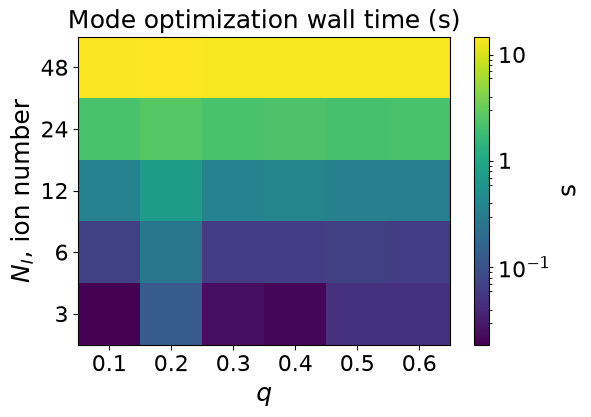

In [44]:
times, equilibria = benchmark_tables()
display(times.head(), equilibria.head())
plot_runtime_heatmap(times, 'analytic_mathieu_anharmonic')
fig.savefig(results_dir/'modes_benchmark_time.eps', dpi=300)
plt.show()

# Part B. Simulation of ion crystals

Runs simulations of ion crystals without cooling according to FFT_SETTINGS. For appropriate frequency resolution, there must be sufficiently large number of steps. Equilibrium positions can be chosen from analytic or Simulated positions, calculated previously. LAMMPS is well suited for multiprocessing simulations, so, provided you have sufficient RAM, choose up to 36 workers (no more than physical cores) (for parallel runs must maintain mpi_processes=1, omp_threads=1). 

In [45]:
FFT_SETTINGS = {
    'evolve_steps': 5_000_000,  # full MD integration length
    'dump_steps': 20,         # fewer text frames; same integration duration / FFT resolution
    'displacement_um': 0.01,
    'equilibrium_source': 'md',  # 'md' (default) or 'analytic'
    'random_seed': 20261109,
    'mpi_processes': 1,
    'omp_threads': 1,
    'frequency_max_hz': Omega / (2*np.pi) * 0.49, # secular band below f_RF/2
    'min_peak_ratio': 1e-7,  # tune only after inspecting spectral peaks
    'min_peak_prominence_ratio': 1e-8,
    'max_peak_candidates_factor': 8, # at most this many candidates per expected mode
    'match_window_hz': 500_000.,
}


def trajectory_path(q, ion_number):
    return output_dir / f'fft_{case_name(q,ion_number)}.lammpstrj'


def trajectory_manifest_path(q, ion_number):
    return results_dir / f'{case_name(q,ion_number)}_trajectory.json'


def _single_ion_md_equilibrium_sidecar(q, arrays, benchmark_meta):
    """Generate/cache MD-relaxed N=1 positions without modifying benchmark arrays.

    Uses the equilibrium integration settings recorded by the finished numerical
    benchmark.
    """
    sidecar = results_dir / f'{case_name(q,1)}_equilibrium_md.npz'
    source_sig = str(benchmark_meta.get('config_signature', ''))
    equilibrium_settings = dict(benchmark_meta.get('settings', BENCHMARK_SETTINGS))
    sidecar_sig = hashlib.sha256(json.dumps({
        'benchmark_signature': source_sig,
        'equilibrium_settings': equilibrium_settings,
        'dc_voltages_v': benchmark_meta['dc_voltages_v'],
        'rf_voltages_v': benchmark_meta['rf_voltages_v'],
        'x1_um': np.asarray(arrays['dc_minimum_um'], float).tolist(),
    }, sort_keys=True).encode('utf-8')).hexdigest()
    if sidecar.exists():
        with np.load(sidecar, allow_pickle=False) as fd:
            recorded_sig = str(fd['input_signature'].item())
            if recorded_sig != sidecar_sig:
                raise ValueError(f'Stale one-ion MD equilibrium sidecar: {sidecar}. '
                                 'Archive it and recompute rather than silently reusing it.')
            pos = np.asarray(fd['positions_md_um'], float)
        if pos.shape != (1, 3) or not np.all(np.isfinite(pos)):
            raise ValueError(f'Invalid one-ion equilibrium sidecar: {sidecar}')
        return pos
    print(f'Calculating missing N=1 MD equilibrium for q={q:g} (once; benchmark preserved)', flush=True)
    pos = equilibrium_positions_from_simulation(
        q, 1, arrays['dc_minimum_um'],
        np.asarray(benchmark_meta['dc_voltages_v'], float),
        np.asarray(benchmark_meta['rf_voltages_v'], float),
        settings=equilibrium_settings)
    pos = np.asarray(pos, float)
    if pos.shape != (1, 3) or not np.all(np.isfinite(pos)):
        raise ValueError(f'MD N=1 equilibrium returned invalid shape/data: {pos.shape}')
    temp = sidecar.with_suffix('.partial.npz')
    with temp.open('wb') as f:
        np.savez_compressed(f, positions_md_um=pos,
                            input_signature=np.array(sidecar_sig))
    os.replace(temp, sidecar)
    return pos


def get_equilibrium_positions_from_data(q, ion_number, source='analytic', units='m'):
    """Load saved equilibrium positions in metres (default) or micrometres.

    source: 'md' or 'analytic'. A missing N=1 MD equilibrium is calculated once
    using the original benchmark's MD settings and stored separately.
    """
    if source not in ('md', 'analytic'):
        raise ValueError("source must be 'md' or 'analytic'")
    arrays, meta = load_case(q, ion_number)
    key = f'positions_{source}_um'
    if key in arrays:
        pos_um = np.asarray(arrays[key], float)
    elif source == 'md' and int(ion_number) == 1:
        pos_um = _single_ion_md_equilibrium_sidecar(q, arrays, meta)
    else:
        raise KeyError(f'{key!r} was not saved for q={q}, N={ion_number}. '
                       'The equilibrium benchmark must be completed first.')
    if pos_um.shape != (int(ion_number), 3) or not np.all(np.isfinite(pos_um)):
        raise ValueError(f'Invalid saved equilibrium positions: {key}: {pos_um.shape}')
    if units == 'm':
        return pos_um * L
    if units == 'um':
        return pos_um.copy()
    raise ValueError("units must be 'm' or 'um'")

def _resolve_registered_dump(q, ion_number, manifest):
    """Find manifest dump, including a moved data folder, without changing the manifest."""
    path = Path(manifest['file_path'])
    if path.is_file():
        return path
    alternatives = [output_dir / path.name]
    if not path.is_absolute():
        alternatives.append(output_dir / path)
    hits = [p for p in dict.fromkeys(alternatives) if p.is_file()]
    if len(hits) == 1:
        return hits[0]
    raise FileNotFoundError(
        f'Registered trajectory for {case_name(q,ion_number)} not found. '        f'Manifest says {path}; tried {alternatives}. '        'Set DATA_DIRECTORY_OVERRIDE to the folder containing the actual files.')


def get_file_path_from_data(q, ion_number):
    """Return the registered MD dump; reject unregistered/missing file paths."""
    manifest_file = trajectory_manifest_path(q, ion_number)
    if not manifest_file.exists():
        raise FileNotFoundError(f'Trajectory manifest missing: {manifest_file}')
    manifest = json.loads(manifest_file.read_text(encoding='utf-8'))
    return _resolve_registered_dump(q, ion_number, manifest)


def register_external_trajectory(q, ion_number, path, dump_steps,
                                 timestep_s=None, evolve_steps=None):
    """Register an existing trajectory from another notebook or earlier run.

    IMPORTANT: make sure its trap voltages/ion number/timestep match this case.
    """
    path = Path(path).resolve()
    if not path.is_file():
        raise FileNotFoundError(path)
    manifest = {
        'q': float(q), 'N': int(ion_number), 'file_path': str(path),
        'dump_steps': int(dump_steps),
        'timestep_s': float(1/(20*Omega) if timestep_s is None else timestep_s),
        'evolve_steps': None if evolve_steps is None else int(evolve_steps),
        'origin': 'external',
    }
    trajectory_manifest_path(q, ion_number).write_text(
        json.dumps(manifest, indent=2), encoding='utf-8')
    return manifest


def _trajectory_input_signature(q, ion_number, settings, source, positions_m,
                                Vrf, dc_set, benchmark_meta):
    """Fingerprint inputs that determine trajectory data, not FFT analysis options."""
    position_bytes = np.ascontiguousarray(positions_m, dtype='<f8').tobytes()
    positions_hash = hashlib.sha256(position_bytes).hexdigest()
    relevant_keys = ('evolve_steps', 'dump_steps', 'displacement_um',
                     'random_seed', 'mpi_processes', 'omp_threads')
    relevant_settings = {k: settings[k] for k in relevant_keys}
    payload = {
        'q': float(q), 'N': int(ion_number), 'Vrf': float(Vrf),
        'dc_voltages_v': np.asarray(dc_set, float).tolist(),
        'Omega_rad_s': float(Omega), 'L_m': float(L),
        'mass_amu': ION_MASS_AMU, 'charge_e': ION_CHARGE_E,
        'benchmark_signature': benchmark_meta.get('config_signature'),
        'equilibrium_source': source,
        'positions_sha256': positions_hash,
        'integration_settings': relevant_settings,
    }
    signature = hashlib.sha256(json.dumps(payload, sort_keys=True).encode('utf-8')).hexdigest()
    return signature, positions_hash


def _simulating_ion_crystal_unlocked(q, ion_number, settings=FFT_SETTINGS, resume=True,
                                      configs=None, equilibrium_source=None):
    """Uncooled full-RF trajectory from selected saved equilibrium positions.

    A completed trajectory is registered via its manifest only after execution.
    """
    N = int(ion_number)
    source = settings.get('equilibrium_source', 'md') if equilibrium_source is None else equilibrium_source
    if source not in ('md', 'analytic'):
        raise ValueError("equilibrium_source must be 'md' or 'analytic'")
    if int(settings['evolve_steps']) < 2 or int(settings['dump_steps']) < 1:
        raise ValueError('Require evolve_steps >= 2 and dump_steps >= 1')
    if int(settings['evolve_steps']) // int(settings['dump_steps']) < 3:
        raise ValueError('Too few dump frames for Fourier extraction')
    path = trajectory_path(q, N)
    manifest_file = trajectory_manifest_path(q, N)
    Vrf, dc_set = configuration_for_q(q, configs)
    arrays, benchmark_meta = load_case(q, N)
    # Check the saved benchmark voltages before using the corresponding equilibrium.
    if (not np.allclose(benchmark_meta['dc_voltages_v'], dc_set, rtol=0, atol=1e-10)
            or not np.allclose(benchmark_meta['rf_voltages_v'], [Vrf,Vrf], rtol=0, atol=1e-10)):
        raise ValueError(f'Saved benchmark voltages differ from config for {case_name(q,N)}')
    positions_m = get_equilibrium_positions_from_data(q, N, source=source, units='m')
    sig, pos_hash = _trajectory_input_signature(q, N, settings, source, positions_m,
                                                Vrf, dc_set, benchmark_meta)
    if manifest_file.exists():
        manifest = json.loads(manifest_file.read_text(encoding='utf-8'))
        existing = _resolve_registered_dump(q, N, manifest)
        if manifest.get('trajectory_signature') != sig:
            raise ValueError(
                f'Existing trajectory {case_name(q,N)} has different or unverified '
                'settings/start positions. Refusing to reuse or overwrite it. '
                f'Existing: steps={manifest.get("evolve_steps")}, '
                f'source={manifest.get("equilibrium_source", "unknown")}; '
                f'requested: steps={settings["evolve_steps"]}, source={source}. '
                'Archive the old dump and manifest, then rerun this case if desired.')
        if resume:
            print(f'SKIP trajectory {case_name(q,N)} (matching manifest, source={source})', flush=True)
            return existing
        raise FileExistsError(f'Completed trajectory already exists: {existing}. '
                              'Archive dump and manifest before rerunning.')
    if path.exists():
        raise FileExistsError(f'{path} exists without a completed manifest. '
                              'Possible interrupted simulation; inspect/archive it first.')

    seed = int(settings['random_seed']) + int(round(float(q)*1000))*10000 + N
    rng = np.random.default_rng(seed)
    displacement_m = L * float(settings['displacement_um']) * rng.uniform(
        -1., 1., size=positions_m.shape)
    starts_m = positions_m + displacement_m
    print(f'RUN trajectory {case_name(q,N)}, steps={settings["evolve_steps"]:,}, '
          f'dump stride={settings["dump_steps"]}, equilibrium={source}', flush=True)
    si = pl.Simulation(str(output_dir / f'modes_{case_name(q,N)}'))
    si.append(pl.placeions({'mass': ION_MASS_AMU, 'charge': ION_CHARGE_E}, starts_m))
    si.append(sn.polygon_trap([Omega, Omega], [Vrf, Vrf], dc_set,
                              RF_electrodes, DC_electrodes))
    si.append(pl.dump(str(path), variables=['x','y','z'],
                      steps=int(settings['dump_steps'])))
    si.append(pl.evolve(int(settings['evolve_steps'])))
    si.execute(mpi_processes=settings['mpi_processes'],
               omp_threads=settings['omp_threads'])
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'LAMMPS finished but dump absent or empty: {path}')
    manifest = {
        'q': float(q), 'N': N, 'file_path': str(path.resolve()),
        'dump_steps': int(settings['dump_steps']),
        'timestep_s': float(1/(20*Omega)),
        'evolve_steps': int(settings['evolve_steps']),
        'rf_omega_rad_s': float(Omega), 'random_seed': seed,
        'displacement_um': float(settings['displacement_um']),
        'equilibrium_source': source,
        'equilibrium_positions_sha256': pos_hash,
        'trajectory_signature': sig,
        'origin': 'SION/pylion', 'created_utc': datetime.now(timezone.utc).isoformat(),
    }
    tmp = manifest_file.with_suffix('.partial.json')
    tmp.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
    os.replace(tmp, manifest_file)
    return path


@contextmanager
def _trajectory_case_lock(q, ion_number):
    """Exclusive per-(q,N) lock to prevent accidental duplicate kernel jobs.

    If a Python/LAMMPS process is forcibly killed, its .lock may remain.
    Remove such a lock only after confirming no job for this case is running.
    """
    path = results_dir / f'{case_name(q,ion_number)}_trajectory.lock'
    try:
        fd = os.open(str(path), os.O_CREAT | os.O_EXCL | os.O_WRONLY)
    except FileExistsError as exc:
        raise RuntimeError(f'Another kernel may be running {case_name(q,ion_number)}. '
                           f'Case lock exists: {path}') from exc
    try:
        with os.fdopen(fd, 'w', encoding='utf-8') as f:
            f.write(f'pid={os.getpid()} utc={datetime.now(timezone.utc).isoformat()}\n')
        yield
    finally:
        path.unlink(missing_ok=True)


def simulating_ion_crystal(q, ion_number, settings=FFT_SETTINGS, resume=True,
                            configs=None, equilibrium_source=None):
    """Public entrypoint: serialize same-case jobs across notebook processes."""
    with _trajectory_case_lock(q, ion_number):
        return _simulating_ion_crystal_unlocked(
            q, ion_number, settings=settings, resume=resume,
            configs=configs, equilibrium_source=equilibrium_source)


def run_trajectories(configs=configurations, resume=True, stop_on_error=False,
                     limit_cases=None, settings=FFT_SETTINGS, q_values=None,
                     ion_numbers=None, case_pairs=None, equilibrium_source=None, workers=36):
    """Run selected cases; per-selection failure logs avoid cross-kernel writes."""
    cases = selected_cases(configs, q_values=q_values, ion_numbers=ion_numbers,
                           case_pairs=case_pairs)
    if limit_cases is not None:
        cases = cases[:int(limit_cases)]
    failures = _run_md_jobs(simulating_ion_crystal,cases,
        dict(settings=settings,resume=resume,configs=configs,equilibrium_source=equilibrium_source),
        workers=workers,stop_on_error=stop_on_error)
    # Unique per selection, not a shared trajectory_failures.json written by 6 kernels.
    selection_token = '__'.join(case_name(q, N) for q,N in cases)
    if not selection_token:
        selection_token = 'empty'
    if len(selection_token) > 110:
        selection_token = 'subset_' + hashlib.sha256(selection_token.encode()).hexdigest()[:16]
    log_path = results_dir / f'trajectory_failures_{selection_token}.json'
    tmp = log_path.with_suffix('.partial.json')
    tmp.write_text(json.dumps(failures, indent=2), encoding='utf-8')
    os.replace(tmp, log_path)
    return failures

## Verification run

Performs trajectory simulations for FFT.

**Long run WARNING: took 24 hours for me**

In [46]:
# SELECT YOUR WORKLOAD HERE. One process per independent trajectory.
# Start with 2–4 workers to check disk throughput, RAM and LAMMPS behavior.
FFT_WORKERS = 36
RUN_QS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6] # choose among [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
RUN_ION_NUMBERS = [1, 3, 6, 12, 24, 48]  # choose among [1, 3, 6, 12, 24, 48]
# Alternative for an arbitrary subset:
# RUN_CASE_PAIRS = [(0.1, 1), (0.1, 6), (0.3, 3)]
RUN_CASE_PAIRS = None

run_jobs = selected_cases(configurations, q_values=None if RUN_CASE_PAIRS else RUN_QS,
                         ion_numbers=None if RUN_CASE_PAIRS else RUN_ION_NUMBERS,
                         case_pairs=RUN_CASE_PAIRS)
print(f'Selected {len(run_jobs)} FFT trajectories:')
for q, N in run_jobs:
    manifest_file = trajectory_manifest_path(q, N)
    print(' ', case_name(q, N), 'manifest exists' if manifest_file.exists() else 'not generated')
print('Integration steps:', FFT_SETTINGS['evolve_steps'],
      '| dump stride:', FFT_SETTINGS['dump_steps'],
      '| position source:', FFT_SETTINGS['equilibrium_source'])

# UNCOMMENT TO START THE EXPENSIVE SIMULATIONS IN THIS NOTEBOOK:
# trajectory_failures = run_trajectories(
#     configs=configurations, q_values=None if RUN_CASE_PAIRS else RUN_QS,
#     ion_numbers=None if RUN_CASE_PAIRS else RUN_ION_NUMBERS,
#     case_pairs=RUN_CASE_PAIRS,
#     settings=FFT_SETTINGS, resume=True, stop_on_error=True, workers=FFT_WORKERS,
# )

Selected 36 FFT trajectories:
  q0p100_N001 manifest exists
  q0p100_N003 manifest exists
  q0p100_N006 manifest exists
  q0p100_N012 manifest exists
  q0p100_N024 manifest exists
  q0p100_N048 manifest exists
  q0p200_N001 manifest exists
  q0p200_N003 manifest exists
  q0p200_N006 manifest exists
  q0p200_N012 manifest exists
  q0p200_N024 manifest exists
  q0p200_N048 manifest exists
  q0p300_N001 manifest exists
  q0p300_N003 manifest exists
  q0p300_N006 manifest exists
  q0p300_N012 manifest exists
  q0p300_N024 manifest exists
  q0p300_N048 manifest exists
  q0p400_N001 manifest exists
  q0p400_N003 manifest exists
  q0p400_N006 manifest exists
  q0p400_N012 manifest exists
  q0p400_N024 manifest exists
  q0p400_N048 manifest exists
  q0p500_N001 manifest exists
  q0p500_N003 manifest exists
  q0p500_N006 manifest exists
  q0p500_N012 manifest exists
  q0p500_N024 manifest exists
  q0p500_N048 manifest exists
  q0p600_N001 manifest exists
  q0p600_N003 manifest exists
  q0p600_N

### Shared LAMMPS dump reader

This reader reorders records using the ion ID at every frame. It is the only parser used by Part C. The extraction checks actual sampling steps, coordinates, and the saved manifest. 

In [47]:
def _lammpstrj_to_memmap(path, N, mmap_path, frame_hint=None):
    """Stream a standard LAMMPS custom dump (id,x,y,z) into an on-disk array.

    For an externally generated trajectory without frame_hint, count headers in a
    first pass. No full trajectory or collection of spectra is kept in RAM.
    Returns memory map and saved LAMMPS step numbers.
    """
    path = Path(path)
    if frame_hint is None:
        with path.open('rb') as f:
            frame_hint = sum(line.startswith(b'ITEM: TIMESTEP') for line in f)
    if frame_hint < 2:
        raise ValueError(f'Insufficient frames in {path}: {frame_hint}')
    m = np.memmap(mmap_path, dtype='float64', mode='w+', shape=(frame_hint,N,3))
    steps = np.empty(frame_hint, dtype=np.int64)
    num = 0
    with path.open('r', encoding='utf-8') as fh:
        while True:
            header = fh.readline()
            if not header:
                break
            if header.strip() != 'ITEM: TIMESTEP':
                raise ValueError(f'Expected ITEM: TIMESTEP in {path}; got {header!r}')
            if num >= frame_hint:
                raise ValueError('More frames than allocated; remove frame_hint')
            steps[num] = int(fh.readline())
            if fh.readline().strip() != 'ITEM: NUMBER OF ATOMS':
                raise ValueError('LAMMPS dump missing ITEM: NUMBER OF ATOMS')
            n_atoms = int(fh.readline())
            if n_atoms != N:
                raise ValueError(f'Expected {N} ions, dump has {n_atoms}')
            boundary = fh.readline().strip()
            if not boundary.startswith('ITEM: BOX BOUNDS'):
                raise ValueError(f'Expected ITEM: BOX BOUNDS, got {boundary}')
            for _ in range(3):
                fh.readline()
            columns_line = fh.readline().strip()
            if not columns_line.startswith('ITEM: ATOMS '):
                raise ValueError(f'Expected ITEM: ATOMS, got {columns_line}')
            cols = columns_line.split()[2:]
            try:
                id_col, x_col, y_col, z_col = (cols.index(s) for s in ('id','x','y','z'))
            except ValueError as e:
                raise ValueError(f'Expected id x y z columns, found {cols}') from e
            records = np.fromstring(''.join(fh.readline() for _ in range(N)), sep=' ')
            if records.size != N * len(cols):
                raise ValueError(f'Incomplete frame at timestep {steps[num]}')
            frame = records.reshape(N,len(cols))
            ids = frame[:,id_col].astype(np.int64)
            if np.unique(ids).size != N:
                raise ValueError('Duplicate ion ids in dump frame')
            order = np.argsort(ids)
            m[num] = frame[order][:,[x_col,y_col,z_col]]
            num += 1
    m.flush()
    if num < 2:
        raise ValueError('Fewer than two valid dump frames')
    return m[:num], steps[:num].copy()

# Part C. Verification results

Performes automatic accuaracy estimation, by comparing frequency peaks from trajectory FFTs to calculated normal modes. Each case can be separately examined. 

1. Detects candidate peaks independently for each ion and each axis. A Hann window, local spectral background, and per-channel prominence are used. Candidate discovery is independent of all analytical frequencies.

2. Caches the evidence once. Each case writes a compact FFT cache containing all preliminary per-channel candidates, an ordinary summed-power spectrum, and an equal-channel-normalized spectrum. Subsequent changes to `VERIFY_SETTINGS` require no trajectory re-read; changes to `SPECTRUM_SETTINGS` do.

3. Identifies physical modes. Duplicate frequency detections are grouped per axis first, using a sub-bin tolerance; distinct nearby lines are retained. Cross-axis groups merge only within a smaller unresolved-line tolerance. Accepted candidates are matched to the selected Mathieu spectrum jointly across x, y, z by a polarization-aware, one-to-one assignment. Accepted per-channel Fourier amplitudes determine the principal-axis preference, while amplitude/prominence influence the choice, and a mode can remain unmatched. 

4. Reports matched-only RMSE and coverage. Filled points represent complete mode identification, while hollow points represent cases where not all modes were identified. For the current results, almost modes can be found automatically, so these unidentified modes are believed to not influence RMSE too much.

Avoid tuning per-case thresholds to maximize mode coverage or minimize the Mathieu RMSE. If the data require a documented exception, use `case_overrides` and keep those settings with the results.

In [48]:
from scipy.ndimage import uniform_filter1d

AXES = ('x', 'y', 'z')
SPECTRUM_VERSION = 'individual_fft_v5.0'
MATCH_VERSION = 'mode_assignment_v8.0'

SPECTRUM_SETTINGS = {
    'frequency_min_hz': 1_000.,
    'frequency_max_hz': float(FFT_SETTINGS['frequency_max_hz']),
    'background_bins': 101,          # odd; local smoothed logarithmic noise estimate
    'raw_min_prominence_db': 3.0,
    'raw_min_snr_db': 3.0,
    'raw_min_relative_db': -110.,
    'min_peak_distance_bins': 2,
    'raw_max_events_per_channel': 650,
}

# Final criteria are in physically meaningful per-channel units and relative
# to local background. They are applied to cached candidates, independently of
# any theoretical frequencies. You may override *only these* per case, and the
# actual settings are recorded alongside the verification result.
VERIFY_SETTINGS = {
    'min_snr_db': 12.0,
    'min_prominence_db': 10.0,
    'min_channel_level_db': -78.0,
    'min_amplitude_um': 0.0,
    'merge_bins': 0.65,  # within an axis: never combine two detected lines from one channel
    'cross_axis_merge_bins': 0.55,  # conservative duplicate tolerance across axes
    'anchor_model': 'mathieu_anharmonic',  # or 'mathieu_harmonic'
    # Only the multi-ion comparison uses Mathieu proximity for assigning labels.
    'max_axial_difference_hz': 150_000.,
    'max_transverse_difference_hz': 350_000.,
    'min_window_bins': 6.,
    'frequency_weight': 0.48,
    'evidence_weight': 0.52,
    'axis_mixing_weight': 0.65,      # disfavors labeling a z-dominated peak as y
    'require_axis_evidence': True, # do not claim y/z modes from the wrong axis
    'mixed_mode_purity_threshold': 0.65,  # relax only for genuinely mixed eigenvectors
    'cross_axis_cost': 0.75,
    'min_axis_evidence_fraction': 0.30, # suppress wrong-axis leak-through for pure modes
    'unmatched_mode_cost': 1.05,
    'anchor_source': 'analytic',
    'single_ion_data_first': False,
    'single_ion_min_secular_fraction': 0.05,  # measured FFT amp / initial kick amplitude
}


def _json_safe(obj):
    if isinstance(obj, dict):
        return {str(k): _json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (tuple, list)):
        return [_json_safe(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return _json_safe(obj.tolist())
    if isinstance(obj, (np.floating, float)) and not np.isfinite(obj):
        return None
    if isinstance(obj, np.generic):
        return obj.item()
    return obj


def _subbin_offset(power, index):
    """Three-bin log-parabolic peak refinement, not an uncertainty estimate."""
    i = int(index)
    if i <= 0 or i >= len(power)-1:
        return 0.
    a, b, c = np.log(np.maximum(np.asarray(power[i-1:i+2], float), 1e-300))
    den = a - 2*b + c
    return float(np.clip(0.5*(a-c)/den, -.5, .5)) if abs(den)>1e-12 else 0.


def _extract_single_channel_events(power, amp_um, frequencies_hz, settings, ion, axis):
    """Candidate detection uses measured data only; no model frequencies."""
    band = (frequencies_hz >= settings['frequency_min_hz']) & (frequencies_hz <= settings['frequency_max_hz'])
    bins = np.flatnonzero(band)
    if len(bins) < 5:
        raise ValueError('No secular FFT bins within the specified frequency range.')
    mx = float(power[bins].max())
    if not np.isfinite(mx) or mx <= 0:
        return [], 0.
    db = 10*np.log10(np.maximum(power / mx, 1e-25))
    win = int(settings['background_bins'])
    if win < 5 or win%2 == 0:
        raise ValueError('background_bins must be odd, >= 5')
    local_db = uniform_filter1d(db[bins], size=win, mode='nearest')
    ind, prop = find_peaks(db[bins],
                          height=float(settings['raw_min_relative_db']),
                          prominence=float(settings['raw_min_prominence_db']),
                          distance=int(settings['min_peak_distance_bins']))
    contrast = db[bins[ind]] - local_db[ind]
    keep = contrast >= float(settings['raw_min_snr_db'])
    ind, contrast = ind[keep], contrast[keep]
    prominences = prop['prominences'][keep]
    inds = bins[ind]
    ok = (inds>0) & (inds<len(power)-1)
    inds, contrast, prominences = inds[ok], contrast[ok], prominences[ok]
    if len(inds) > int(settings['raw_max_events_per_channel']):
        rank = np.argsort(contrast + .12*prominences)[-int(settings['raw_max_events_per_channel']):]
        inds,contrast,prominences = inds[rank],contrast[rank],prominences[rank]
    events=[]
    df = float(frequencies_hz[1]-frequencies_hz[0])
    for k,snr,prom in zip(inds,contrast,prominences):
        events.append({
            'frequency_hz': float((k+_subbin_offset(power,k))*df),
            'ion':int(ion), 'axis':AXES[axis],
            'amplitude_um':float(amp_um[k]),
            'local_snr_db':float(snr),
            'prominence_db':float(prom),
            'channel_level_db':float(db[k]),
        })
    return events, float(np.max(amp_um[bins]))


def _cache_path(q,N):
    return fft_cache_dir / (case_name(q,N) + '_individual_fft_v5.npz')


def load_individual_fft_cache_only(q, N):
    """Read an existing analysis cache without opening a multi-GB trajectory.
    """
    cache = _cache_path(q, N)
    if not cache.is_file():
        raise FileNotFoundError(f'Cached FFT missing for {case_name(q,N)}: {cache}')
    with np.load(cache, allow_pickle=False) as fd:
        meta = json.loads(str(fd['metadata_json']))
        if (meta.get('version') != SPECTRUM_VERSION or
                not np.isclose(float(meta.get('q')),float(q),rtol=0,atol=1e-10) or
                int(meta.get('N')) != int(N)):
            raise ValueError(f'FFT cache metadata mismatch: {cache}')
        return {'events':json.loads(str(fd['events_json'])),
                'metadata':meta,
                'power_axes':fd['power_axes'].astype(float),
                'balanced_axes':fd['balanced_axes'].astype(float)}


def collect_individual_fft(q,N,settings=None,resume=True,force=False,cached_only=False):
    """Once per case: parse ion positions, detect per-channel FFT peaks, save compact cache.

    Memory: 3 x (T//2+1) summed spectra plus one channel at a time; dumps are
    streamed to a temporary memmap. Nothing writes over the original trajectory.
    """
    cfg = dict(SPECTRUM_SETTINGS if settings is None else settings)
    q=float(q);N=int(N)
    if cached_only:
        data=load_individual_fft_cache_only(q, N)
        if data['metadata'].get('acquisition_settings') != cfg:
            raise ValueError('Requested FFT extraction settings differ from cache. '
                             'Use the original SPECTRUM_SETTINGS for cached-only processing.')
        return data
    dump_path = get_file_path_from_data(q,N)
    manifest_path = trajectory_manifest_path(q,N)
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    signature = hashlib.sha256(json.dumps({
        'algorithm':SPECTRUM_VERSION,'path':str(dump_path.resolve()),
        'size':dump_path.stat().st_size,'mtime_ns':dump_path.stat().st_mtime_ns,
        'dump_steps':manifest['dump_steps'],'dt_s':manifest['timestep_s'],
        'settings':cfg,
    },sort_keys=True).encode('utf-8')).hexdigest()
    path = _cache_path(q,N)
    if resume and not force and path.exists():
        with np.load(path,allow_pickle=False) as fd:
            if str(fd['signature']) == signature:
                return {'events':json.loads(str(fd['events_json'])),
                        'metadata':json.loads(str(fd['metadata_json'])),
                        'power_axes':fd['power_axes'].astype(float),
                        'balanced_axes':fd['balanced_axes'].astype(float)}
        print(f'{case_name(q,N)}: cache signature changed; extracting again')
    stride=int(manifest['dump_steps'])
    dt=float(manifest['timestep_s'])
    hint=manifest.get('evolve_steps')
    if hint is not None: hint=int(hint)//stride+2
    scratch=fft_cache_dir / (f'{case_name(q,N)}_{os.getpid()}_individual.mmap')
    mmap=None
    try:
        mmap,steps=_lammpstrj_to_memmap(dump_path,N,scratch,frame_hint=hint)
        if len(steps)<10 or np.any(np.diff(steps)!=stride):
            raise ValueError('Insufficient frames or nonuniform trajectory sampling')
        frames=len(steps)
        fsample=dt*stride
        freqs=np.fft.rfftfreq(frames,d=fsample)
        if float(cfg['frequency_max_hz']) >= 0.5/fsample:
            raise ValueError('Requested band exceeds Nyquist: change dump stride or frequency_max_hz')
        window=np.hanning(frames)
        wsum=window.sum()
        power_axes=np.zeros((3,len(freqs)),dtype=np.float64)
        balanced_axes=np.zeros_like(power_axes)
        events=[]
        maxima=np.zeros((N,3),float)
        rms=np.zeros((N,3),float)
        for ion in range(N):
            for a in range(3):
                signal=np.array(mmap[:,ion,a],dtype=float,copy=True)  # release Windows memmap lock
                centred=signal - np.mean(signal)
                rms[ion,a]=np.sqrt(np.mean(centred**2))/L
                amplitude=2*np.abs(np.fft.rfft(centred*window))/wsum/L
                p=amplitude**2
                power_axes[a] += p
                band=(freqs>=cfg['frequency_min_hz'])&(freqs<=cfg['frequency_max_hz'])
                high=max(float(np.max(p[band])),np.finfo(float).tiny)
                # Equal-channel-normalized power is for display ONLY.
                if np.max(amplitude)>0:
                    balanced_axes[a] += p/high
                ev, mx = _extract_single_channel_events(p,amplitude,freqs,cfg,ion,a)
                maxima[ion,a]=mx
                events.extend(ev)
        meta = {
            'version':SPECTRUM_VERSION,'q':q,'N':N,'df_hz':float(freqs[1]-freqs[0]),
            'sample_dt_s':fsample,'frames':int(frames),
            'start_step':int(steps[0]),'end_step':int(steps[-1]),
            'channel_rms_um':rms.tolist(),
            'channel_max_fft_amplitude_um':maxima.tolist(),
            'signature':signature,'acquisition_settings':cfg,
            'n_raw_channel_events':len(events),
        }
        tmp=path.with_suffix('.partial.npz')
        with open(tmp,'wb') as fh:
            np.savez_compressed(fh,signature=np.array(signature),
                events_json=np.array(json.dumps(events,separators=(',',':'))),
                metadata_json=np.array(json.dumps(meta,separators=(',',':'))),
                power_axes=power_axes.astype(np.float32),
                balanced_axes=balanced_axes.astype(np.float32))
        os.replace(tmp,path)
        print(f'{case_name(q,N)}: cached {len(events):,} channel peaks from {frames:,} frames')
        return {'events':events,'metadata':meta,'power_axes':power_axes,'balanced_axes':balanced_axes}
    finally:
        if mmap is not None:
            mmap.flush();del mmap
        if scratch.exists():
            try:scratch.unlink()
            except PermissionError:print('Temporary memmap still open:',scratch)


def _event_pool(data,settings):
    """Filter independent channel detections, then merge the same measured frequency.

    Multiple ions detecting the same line provide corroboration. A single strong
    channel is still eligible; requiring 2 ions would incorrectly reject a
    localized mode. The acquisition thresholds and final thresholds differ.
    """
    passed=[]
    for e in data['events']:
        if (e['local_snr_db'] >= settings['min_snr_db'] and
            e['prominence_db'] >= settings['min_prominence_db'] and
            e['channel_level_db'] >= settings['min_channel_level_db'] and
            e['amplitude_um'] >= settings['min_amplitude_um']):
            passed.append(e)

    df=float(data['metadata']['df_hz'])
    tol=float(settings['merge_bins'])*df
    cross_tol=float(settings.get('cross_axis_merge_bins',0.55))*df
    if not (0 < tol <= df and 0 < cross_tol <= df):
        raise ValueError('Use merge tolerances between zero and one FFT bin.')
    axis_groups=[]
    for axis in AXES:
        groups=[]
        for e in sorted((e for e in passed if e['axis']==axis),key=lambda e:e['frequency_hz']):
            if (groups and e['frequency_hz']-groups[-1][0]['frequency_hz']<=tol
                    and e['ion'] not in {z['ion'] for z in groups[-1]}):
                groups[-1].append(e)
            else:
                groups.append([e])
        for g in groups:
            center=float(np.average([e['frequency_hz'] for e in g],
                      weights=[min(max(e['local_snr_db'],1),50) for e in g]))
            axis_groups.append((center,axis,g))

    grouped=[]
    for center,axis,g in sorted(axis_groups,key=lambda z:z[0]):
        eligible=[z for z in grouped if axis not in z['axes'] and
                  center-z['centers'][0]<=cross_tol]
        if eligible:
            z=min(eligible,key=lambda z:abs(center-np.mean(z['centers'])))
            z['axes'].add(axis);z['centers'].append(center);z['events'].extend(g)
        else:
            grouped.append(dict(axes={axis},centers=[center],events=list(g)))
    clusters=[z['events'] for z in grouped]
    candidates=[]
    for group in clusters:
        # Each axis has its OWN evidence. A strong z signal cannot stand in for y.
        weights=np.array([min(max(e['local_snr_db'],1),50) for e in group])
        freq=float(np.average([e['frequency_hz'] for e in group],weights=weights))
        support={a:len({e['ion'] for e in group if e['axis']==a}) for a in AXES}
        best=max(group,key=lambda e:(e['local_snr_db'],e['amplitude_um']))
        per_axis={}
        for axis in AXES:
            ev=[e for e in group if e['axis']==axis]
            if not ev:continue
            best_ev=max(ev,key=lambda e:(e['local_snr_db'],e['channel_level_db']))
            per_axis[axis]={
                'snr_db':float(best_ev['local_snr_db']),
                'prominence_db':float(max(e['prominence_db'] for e in ev)),
                'level_db':float(max(e['channel_level_db'] for e in ev)),
                'amplitude_um':float(max(e['amplitude_um'] for e in ev)),
                'n_ions':int(support[axis]),
                'frequency_hz':float(np.average([e['frequency_hz'] for e in ev],
                    weights=[min(max(e['local_snr_db'],1),50) for e in ev])),
                'power_um2':float(sum(max(e['amplitude_um']**2 for e in ev if e['ion']==i)
                    for i in {e['ion'] for e in ev})),
            }

        participation=np.array([per_axis.get(a,{}).get('power_um2',0.) for a in AXES])
        frac=participation/max(float(participation.sum()),np.finfo(float).tiny)
        candidates.append({
            'frequency_hz':freq,
            'best_snr_db':max(e['local_snr_db'] for e in group),
            'best_prominence_db':max(e['prominence_db'] for e in group),
            'max_amplitude_um':max(e['amplitude_um'] for e in group),
            'n_ions':len({e['ion'] for e in group}),
            'n_channels':len({(e['ion'],e['axis']) for e in group}),
            'axis_support':support,'axis_fraction':frac.tolist(),
            'axis_evidence':per_axis,'best_axis':AXES[int(np.argmax(frac))],
            'axis_power_um2':participation.tolist(),
            'spread_hz':max(e['frequency_hz'] for e in group)-min(e['frequency_hz'] for e in group),
        })
    return candidates, len(passed)

In [49]:
def _mode_axis_classification(mode_vectors,N):
    """Assign N predominantly-polarized eigenvectors to each axis. SION rows
    are modes and columns are [all-x ions, all-y ions, all-z ions]."""
    N=int(N)
    vec=np.abs(np.asarray(mode_vectors))**2
    if vec.shape!=(3*N,3*N):
        raise ValueError('Mode-vector array shape does not match (3N, 3N)')
    norms=vec.sum(axis=1)
    if np.any(norms<=0):raise ValueError('Zero-norm mode vector')
    weights=np.column_stack([vec[:,a*N:(a+1)*N].sum(axis=1)/norms for a in range(3)])
    slots=np.repeat(np.arange(3),N)
    rows,cols=linear_sum_assignment(-weights[:,slots])
    out={}
    for a,axis in enumerate(AXES):
        ix=rows[slots[cols]==a]
        out[axis]={'indices':ix,'purity':weights[ix,a]}
    return out


def _single_ion_mode_groups(q, arrays, model):
    """Use saved N=1 eigenvectors, or recompute with correctly normalized RF."""
    key = 'analytic_' + model
    if 'modes_' + key in arrays:
        vec = np.asarray(arrays['modes_' + key])
    else:
        system, _, _, _, _, rf_set, dcs = make_system(q)
        position = np.asarray(arrays['dc_minimum_um'], float)
        h, hv, m, mv = _single_ion_theory_from_system(system, position, dcs, rf_set)
        if model not in ('harmonic', 'single_ion_mathieu'):
            raise ValueError(f'Unsupported single-ion model: {model}')
        f, vec = (h, hv) if model == 'harmonic' else (m, mv)
        saved = np.asarray(arrays['freq_'+key+'_hz'], float)
        if not np.allclose(saved, f, rtol=1e-5, atol=100):
            raise ValueError('Saved single-ion frequencies differ from current '
                             'correctly RF-normalized calculation. Run '
                             'run_benchmark() with resume=False for the N=1 cases.')
    return _mode_axis_classification(vec, 1)


def _theory_groups(q,N,arrays,source,model):
    key=f'{source}_{model}'
    freqs=np.asarray(arrays['freq_'+key+'_hz'],float)
    groups=(_single_ion_mode_groups(q,arrays,model) if N==1 else
            _mode_axis_classification(arrays['modes_'+key],N))
    out={}
    for ax in AXES:
        idx=groups[ax]['indices']
        order=np.argsort(freqs[idx])
        out[ax]={'freq_hz':np.asarray(freqs[idx[order]],float),
                 'indices':np.asarray(idx[order],int),
                 'purity':np.asarray(groups[ax]['purity'][order],float)}
    return out



def _candidate_axis_quality(candidate, axis, settings, N):
    """Score from measured evidence ON THAT AXIS, never from another axis."""
    evidence=candidate.get('axis_evidence',{}).get(axis)
    if evidence is None:
        return None
    snr=np.clip((evidence['snr_db']-settings['min_snr_db'])/30.,0,1)
    prom=np.clip((evidence['prominence_db']-settings['min_prominence_db'])/35.,0,1)
    level=np.clip((evidence['level_db']-settings['min_channel_level_db'])/
                  max(1.,-settings['min_channel_level_db']),0,1)
    participation=np.clip(np.log1p(evidence['n_ions'])/np.log1p(max(2,N)),0,1)
    return float(.30*snr+.20*prom+.38*level+.12*participation)


def _assignment_cost(mode,candidate,settings,df_hz,N):
    axis=mode['axis']
    axis_ev=candidate.get('axis_evidence',{})
    quality=_candidate_axis_quality(candidate,axis,settings,N)
    cross_axis=False
    if quality is None:
        # Only a genuinely mixed y/z eigenvector may use a peak observed
        # exclusively on the opposite transverse axis. Never cross into x.
        if (settings['require_axis_evidence'] or axis=='x' or
            float(mode.get('purity',1.))>=settings['mixed_mode_purity_threshold']):
            return np.inf
        partner='z' if axis=='y' else 'y'
        quality=_candidate_axis_quality(candidate,partner,settings,N)
        if quality is None:return np.inf
        cross_axis=True
    if (quality is not None and not cross_axis and
        candidate['axis_fraction'][AXES.index(axis)] < settings['min_axis_evidence_fraction'] and
        float(mode.get('purity',1.)) >= settings['mixed_mode_purity_threshold']):
        return np.inf
    if N==1 and settings.get('single_ion_data_first',True):
        # Reject sub-kick noise peaks in the secular band. A visible RF carrier
        # does NOT independently establish a secular mode.
        ev=candidate.get('axis_evidence',{}).get(axis)
        if ev is None:return np.inf
        kick=float(mode.get('initial_kick_um',0.))
        if kick>0 and ev['amplitude_um']<kick*float(settings['single_ion_min_secular_fraction']):
            return np.inf


        return float(1.-quality+.35*(1-candidate['axis_fraction'][AXES.index(axis)])+
                     (settings['cross_axis_cost'] if cross_axis else 0.))
    window=max(float(settings['min_window_bins'])*df_hz,
               float(settings['max_axial_difference_hz'] if axis=='x' else
                     settings['max_transverse_difference_hz']))
    observed=axis_ev.get(axis,{}).get('frequency_hz',candidate['frequency_hz'])
    delta=abs(mode['frequency_hz']-observed)
    if delta>window:return np.inf
    axis_fraction=float(candidate['axis_fraction'][AXES.index(axis)])
    return float(settings['frequency_weight']*delta/window+
                 settings['evidence_weight']*(1-quality)+
                 settings['axis_mixing_weight']*(1-axis_fraction)+
                 (settings['cross_axis_cost'] if cross_axis else 0.))


def _assign_mode_candidates(modes,candidates,df_hz,settings,N):
    """One-to-one assignment using evidence and per-mode polarization.

    The three axes share a candidate pool; a peak cannot be assigned twice.
    Unlike a globally monotone DP, an RF-induced crossing of y/z theoretical
    branches does not exclude an otherwise justified individual-axis peak.
    After assignment, observed modes are sorted within their own axes.
    """
    modes=sorted(modes,key=lambda m:(AXES.index(m['axis']),m['rank']))
    candidates=sorted(candidates,key=lambda c:c['frequency_hz'])
    n=len(modes);k=len(candidates)
    if n==0:return modes,candidates,{}
    penalty=float(settings['unmatched_mode_cost'])
    if penalty<=0:raise ValueError('unmatched_mode_cost must be positive')
    # Dedicated unmatched column for EACH mode avoids artificial full coverage.
    cost=np.full((n,k+n),penalty+1e5,dtype=float)
    cost[:,k:]=penalty
    fs=np.array([c['frequency_hz'] for c in candidates],float)
    for i,mode in enumerate(modes):
        if N==1 and settings.get('single_ion_data_first',True):
            indices=range(k)
        else:
            bound=max(settings['min_window_bins']*df_hz,
                      settings['max_axial_difference_hz'] if mode['axis']=='x' else
                      settings['max_transverse_difference_hz'])
            lo=int(np.searchsorted(fs,mode['frequency_hz']-bound-df_hz,'left'))
            hi=int(np.searchsorted(fs,mode['frequency_hz']+bound+df_hz,'right'))
            indices=range(lo,hi)
        for j in indices:
            candidate=candidates[j]
            c=_assignment_cost(mode,candidate,settings,df_hz,N)
            if np.isfinite(c):cost[i,j]=c
    rows,columns=linear_sum_assignment(cost)
    matches={}
    for i,j in zip(rows,columns):
        if j<k and cost[i,j]<penalty:
            matches[(modes[i]['axis'],modes[i]['rank'])]=int(j)

    for axis in AXES:
        ix=[i for i,m in enumerate(modes) if m['axis']==axis and (axis,m['rank']) in matches]
        for _ in range(len(ix)):
            changed=False
            for i,j in zip(ix,ix[1:]):
                a,b=(axis,modes[i]['rank']),(axis,modes[j]['rank'])
                u,v=matches[a],matches[b]
                fu=candidates[u].get('axis_evidence',{}).get(axis,{}).get('frequency_hz',candidates[u]['frequency_hz'])
                fv=candidates[v].get('axis_evidence',{}).get(axis,{}).get('frequency_hz',candidates[v]['frequency_hz'])
                if fu>fv and cost[i,v]<penalty and cost[j,u]<penalty:
                    matches[a],matches[b]=v,u;changed=True
            if not changed:break

    return modes,candidates,matches

def _scores(pred,obs,df_hz):
    pred=np.asarray(pred,float);obs=np.asarray(obs,float)
    matched=np.isfinite(obs)
    num=int(matched.sum());expected=len(pred)
    diff=pred[matched]-obs[matched]
    partial=float(np.sqrt(np.mean(diff**2))) if num else None
    return {'n_matched':num,'n_expected':expected,'coverage':num/expected if expected else 0.,
            'matched_rmse_hz':partial,
            'full_rmse_hz':partial if num==expected else None,
            'mean_abs_error_hz':float(np.mean(np.abs(diff))) if num else None,
            'rmse_bins':float(partial/df_hz) if num else None,
            'observed_hz':_json_safe(obs),
            'predicted_hz':_json_safe(pred),
            'residual_hz':_json_safe(pred-obs)}


def verify_modes(q,N,settings=None,save=True,spectrum_settings=None,
                 cached_spectrum_only=False):
    """One definitive analysis: channel evidence -> merged peaks -> feasible labels.
    All predictions are compared against the SAME labeled observed frequencies.
    Selecting labels with the Mathieu model makes its RMSE conditional.
    """
    cfg=dict(VERIFY_SETTINGS if settings is None else settings)
    q=float(q);N=int(N)
    arrays,benchmark_meta=load_case(q,N)
    if N==1 and benchmark_meta.get('single_ion_rf_units') != 'normalized electrode.System coefficients':
        raise RuntimeError('N=1 benchmark contains old incorrectly RF-scaled Mathieu modes. '
                           'Regenerate the N=1 benchmark using the corrected solver.')
    data=collect_individual_fft(q,N,settings=spectrum_settings,
                                cached_only=cached_spectrum_only)
    candidates,n_events=_event_pool(data,cfg)
    anchor_model='single_ion_mathieu' if N==1 else cfg.get('anchor_model','mathieu_anharmonic')
    if N>1 and anchor_model not in ('mathieu_harmonic','mathieu_anharmonic'):
        raise ValueError('anchor_model must be mathieu_harmonic or mathieu_anharmonic')
    anchor_source='analytic' if N==1 else cfg['anchor_source']
    theory=_theory_groups(q,N,arrays,anchor_source,anchor_model)
    kick_um=np.zeros(3,float)
    if N==1 and cfg.get('single_ion_data_first',False):
        manifest_path=trajectory_manifest_path(q,N)
        if manifest_path.is_file():
            manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
            if 'random_seed' in manifest and 'displacement_um' in manifest:
                kick_um=np.abs(np.random.default_rng(int(manifest['random_seed']))
                               .uniform(-1,1,(1,3)).ravel()*float(manifest['displacement_um']))
    modes=[]
    for a in AXES:
        for i, f in enumerate(theory[a]['freq_hz']):
            modes.append({'axis':a,'rank':i,'frequency_hz':float(f),
                          'purity':float(theory[a]['purity'][i]),
                          'initial_kick_um':float(kick_um[AXES.index(a)])})
    ordered_modes,ordered_candidates,assign=_assign_mode_candidates(
        modes,candidates,float(data['metadata']['df_hz']),cfg,N)
    per_axis={}
    used=set(assign.values())
    for axis in AXES:
        mode_freqs=theory[axis]['freq_hz']
        selected=[assign.get((axis,i)) for i in range(N)]
        obs=np.array([ordered_candidates[ix]['axis_evidence'].get(axis,{}).get('frequency_hz',ordered_candidates[ix]['frequency_hz']) if ix is not None
                      else np.nan for ix in selected],float)
        per_axis[axis]={
            'observed_hz':_json_safe(obs),
            'anchor_hz':_json_safe(mode_freqs),
            'mode_indices':np.asarray(theory[axis]['indices'],int).tolist(),
            'mode_purities':_json_safe(theory[axis]['purity']),
            'assigned_candidate_indices':selected,
            'assigned_axis_evidence':[_json_safe(ordered_candidates[ix].get('axis_evidence',{}).get(axis))
                                      if ix is not None else None for ix in selected],
            'n_matched':int(np.isfinite(obs).sum()),
            'n_expected':N,
        }
    # Report crowding independently of the optimizer. A near-neighbor line
    # may be resolved in different channels, but its frequency uncertainty is
    # higher than that of an isolated line. No duplicate observations created.
    centers=np.array([c['frequency_hz'] for c in ordered_candidates],float)
    for j,c in enumerate(ordered_candidates):
        nearest=min(centers[j]-centers[j-1] if j else np.inf,
                    centers[j+1]-centers[j] if j+1<len(centers) else np.inf)
        c['nearest_candidate_spacing_bins']=float(nearest/data['metadata']['df_hz']) if np.isfinite(nearest) else None
        c['crowded']=bool(nearest<2*data['metadata']['df_hz'])
    # Annotate unassigned good candidates; never silently hide them.
    for j,c in enumerate(ordered_candidates):
        c['assigned']=(j in used)
        if c['assigned']:
            assigned=[f"{ax}{r+1}" for (ax,r),v in assign.items() if v==j]
            c['status']='assigned:'+','.join(assigned)
            c['assigned_axis']=next(ax for (ax,r),v in assign.items() if v==j)
            c['cross_axis_evidence']=len(c['axis_evidence'])>1
            c['assigned_axis_power_fraction']=c['axis_fraction'][AXES.index(c['assigned_axis'])]
        else:
            near=min(ordered_modes,key=lambda m:abs(m['frequency_hz']-c['frequency_hz']))
            win=cfg['max_axial_difference_hz'] if near['axis']=='x' else cfg['max_transverse_difference_hz']
            c['nearest_predicted_mode']=f"{near['axis']}{near['rank']+1}"
            c['nearest_delta_khz']=float((c['frequency_hz']-near['frequency_hz'])/1e3)
            c['status']=('outside matching range' if abs(c['frequency_hz']-near['frequency_hz'])>max(win,cfg['min_window_bins']*data['metadata']['df_hz'])
                         else 'unused: other peak preferred / one-to-one axis-evidence assignment')
    models=('harmonic','single_ion_mathieu') if N==1 else ('harmonic','mathieu_harmonic','mathieu_anharmonic')
    sources=('analytic',) if N==1 else ('analytic','md')
    comparison={}
    for source in sources:
        for model in models:
            key=f'{source}_{model}'
            if 'freq_'+key+'_hz' not in arrays:continue
            current=_theory_groups(q,N,arrays,source,model)
            stats={}
            for ax in AXES:
                prediction=current[ax]['freq_hz']
                observed=np.array([float(z) if z is not None else np.nan for z in per_axis[ax]['observed_hz']])
                stats[ax]=_scores(prediction,observed,float(data['metadata']['df_hz']))
            joined_pred=np.concatenate([current[a]['freq_hz'] for a in AXES])
            joined_obs=np.concatenate([[np.nan if x is None else x for x in per_axis[a]['observed_hz']] for a in AXES])
            stats['all']=_scores(joined_pred,joined_obs,float(data['metadata']['df_hz']))
            comparison[key]=stats
    result={
        'version':MATCH_VERSION,'q':q,'N':N,'df_hz':float(data['metadata']['df_hz']),
        'spectrum_cache_signature':data['metadata']['signature'],
        'spectrum_settings':data['metadata']['acquisition_settings'],
        'verification_settings':cfg,'label_model':f'{anchor_source}_{anchor_model}',
        'n_channel_events_passed':n_events,'n_unique_candidates':len(ordered_candidates),
        'n_assigned':len(assign),'n_expected':3*N,
        'n_assigned_crowded':sum(bool(ordered_candidates[j]['crowded']) for j in used),
        'mode_references':per_axis,'candidates':ordered_candidates,'models':comparison,
        'caveat':('N=1 frequencies selected using data-only axis evidence; check theoretical single-ion frequencies.' if N==1 and cfg['single_ion_data_first']
                  else 'Peak discovery is data-only; mode labels use Mathieu predictions, so anchor RMSE is conditional, not independent validation.')
    }
    if save:
        path=results_dir / (case_name(q,N)+'_verification_final_v8.json')
        tmp=path.with_suffix('.partial.json')
        tmp.write_text(json.dumps(_json_safe(result),indent=2,allow_nan=False),encoding='utf-8')
        os.replace(tmp,path)
    return result


def verify_selected_cases(case_pairs=None,q_values=None,ion_numbers=None,
                          settings=None,case_overrides=None,stop_on_error=False,
                          cached_spectrum_only=False):
    chosen=selected_cases(configurations,case_pairs=case_pairs,
                          q_values=q_values,ion_numbers=ion_numbers)
    failures=[]
    base=dict(VERIFY_SETTINGS if settings is None else settings)
    overrides={} if case_overrides is None else case_overrides
    for q,N in chosen:
        try:
            case_settings={**base,**overrides.get((float(q),int(N)),{})}
            r=verify_modes(q,N,settings=case_settings,
                           cached_spectrum_only=cached_spectrum_only)
            label=' '.join(f'{ax}:{r["mode_references"][ax]["n_matched"]}/{N}' for ax in AXES)
            print(f'{case_name(q,N)}: {label}, assigned {r["n_assigned"]}/{3*N} '
                  f'(candidates {r["n_unique_candidates"]})')
        except Exception as e:
            failures.append({'q':q,'N':N,'error':repr(e)})
            print('ERROR',case_name(q,N),repr(e))
            if stop_on_error:raise
    return failures


def load_final_verification(q,N):
    path=results_dir / (case_name(q,N)+'_verification_final_v8.json')
    return json.loads(path.read_text(encoding='utf-8'))


def verification_table(case_pairs=None,save_csv=True):
    cases=selected_cases(configurations,case_pairs=case_pairs)
    rows=[]
    for q,N in cases:
        path=results_dir / (case_name(q,N)+'_verification_final_v8.json')
        if not path.is_file():continue
        r=json.loads(path.read_text(encoding='utf-8'))
        for key,methods in r['models'].items():
            for axis,metric in methods.items():
                rows.append({'q':q,'N':N,'source_model':key,'axis':axis,
                             'n_matched':metric['n_matched'],'n_expected':metric['n_expected'],
                             'coverage':metric['coverage'],
                             'matched_rmse_khz':None if metric['matched_rmse_hz'] is None else metric['matched_rmse_hz']/1e3,
                             'full_rmse_khz':None if metric['full_rmse_hz'] is None else metric['full_rmse_hz']/1e3,
                             'note':('N=1 corrected RF normalization; Mathieu-assisted labels (conditional)' if N==1 else 'Mathieu-assisted labels (conditional mode accuracy)')})
    df=pd.DataFrame(rows)
    if save_csv and not df.empty:
        df.to_csv(results_dir/'verification_final_v8.csv',index=False)
    return df


def candidate_table(q,N,only_unassigned=False):
    r=load_final_verification(q,N)
    df=pd.DataFrame(r['candidates'])
    if only_unassigned and not df.empty:df=df[~df['assigned']]
    if df.empty:return df
    return df.assign(f_MHz=df['frequency_hz']/1e6).sort_values('frequency_hz')[[
        'f_MHz','status','best_snr_db','best_prominence_db','max_amplitude_um',
        'n_ions','n_channels','axis_support','axis_fraction','best_axis','axis_evidence','nearest_delta_khz'] if
        'nearest_delta_khz' in df.columns else [
        'f_MHz','status','best_snr_db','best_prominence_db','max_amplitude_um',
        'n_ions','n_channels','axis_support','axis_fraction','best_axis','axis_evidence']]

def com_consistency_table(case_pairs=None, save_csv=True):
    """Compare COM-like modes with the single-ion reference; no MD or solver rerun.
    COM-like = largest squared overlap with a uniform Cartesian displacement.
    In an anharmonic trap this need not be an exact COM eigenmode or a band edge.
    MD values are assigned spectral peaks, not an independent COM projection.
    """
    rows=[]
    for q,N in selected_cases(configurations,case_pairs=case_pairs):
        if not case_path(q,N).exists() or not case_path(q,1).exists():continue
        arrays,meta=load_case(q,N);one,_=load_case(q,1)
        try:r=load_final_verification(q,N)
        except FileNotFoundError:r=None
        ref_models=('harmonic','single_ion_mathieu')
        one_groups={m:_theory_groups(q,1,one,'analytic',m) for m in ref_models}
        models=ref_models if N==1 else ('harmonic','mathieu_harmonic','mathieu_anharmonic')
        for source in ('analytic',) if N==1 else ('analytic','md'):
            for model in models:
                key=f'{source}_{model}'
                if 'modes_'+key not in arrays:continue
                v=np.asarray(arrays['modes_'+key]);norm=np.sum(abs(v)**2,axis=1)
                groups=_theory_groups(q,N,arrays,source,model)
                for a,axis in enumerate(AXES):
                    g=groups[axis];ids=g['indices']
                    overlap=abs(np.sum(v[ids,a*N:(a+1)*N],axis=1))**2/(N*np.maximum(norm[ids],1e-300))
                    j=int(np.argmax(overlap));f=float(g['freq_hz'][j]);
                    single=float(one_groups['harmonic' if model=='harmonic' else 'single_ion_mathieu'][axis]['freq_hz'][0])
                    observed=None if r is None else r['models'].get(key,{}).get(axis,{}).get('observed_hz',[None]*N)[j]
                    rows.append(dict(q=q,N=N,source=source,model=model,axis=axis,rank=j+1,
                        com_overlap=float(overlap[j]),com_khz=f/1e3,single_khz=single/1e3,
                        com_minus_single_khz=(f-single)/1e3,assigned_md_khz=None if observed is None else observed/1e3,
                        com_minus_assigned_md_khz=None if observed is None else (f-observed)/1e3,
                        center_offset_um=(meta.get('position_comparison') or {}).get('center_offset_um')))
    out=pd.DataFrame(rows)
    if save_csv and not out.empty:out.to_csv(results_dir/'com_consistency_v8.csv',index=False)
    return out


def _local_hessian_floquet_reference(system, positions_m, full_dcs, rf, r=2):
    """Optional diagnostic: linearize the actual electrode potentials locally.

    Exact spatial second derivatives at the supplied *static* positions,
    combined with the analytical Coulomb Hessian; Floquet truncation r=2.
    This is not a linearization about the full RF-periodic crystal orbit and
    is NOT used in peak selection or the three published model RMSE curves.
    """
    p=np.asarray(positions_m,float);N=len(p)
    if p.shape!=(N,3) or N<1:raise ValueError('Expected (N,3) SI positions')
    A=np.zeros((3*N,3*N));Q=np.zeros_like(A);C=np.zeros_like(A)
    with system.with_voltages(dcs=full_dcs,rfs=np.asarray(rf,float)):
        for i,pos in enumerate(p):
            ids=np.arange(3)*N+i
            A[np.ix_(ids,ids)]=np.asarray(system.electrical_potential(pos/L,'dc',2,expand=True)[0],float)*Z/L**2
            Q[np.ix_(ids,ids)]=np.asarray(system.electrical_potential(pos/L,'rf',2,expand=True)[0],float)*Z/L**2
    for i in range(N):
        ii=np.arange(3)*N+i
        for j in range(i+1,N):
            jj=np.arange(3)*N+j;d=p[i]-p[j];distance=np.linalg.norm(d)
            if distance<=0:raise ValueError('Overlapping ions in saved equilibrium')
            H=(Z**2/(4*np.pi*ct.epsilon_0))*(3*np.outer(d,d)/distance**5-np.eye(3)/distance**3)
            C[np.ix_(ii,ii)]+=H;C[np.ix_(jj,jj)]+=H
            C[np.ix_(ii,jj)]-=H;C[np.ix_(jj,ii)]-=H
    mu,b=sn.mathieu_solver(int(r),4*(A+C)/(mass*Omega**2),2*Q/(mass*Omega**2))
    mu=np.asarray(mu);ix=np.flatnonzero(mu.imag>0);ix=ix[np.argsort(mu[ix].imag)][:3*N]
    if len(ix)!=3*N:raise ValueError('Insufficient positive Floquet frequencies')
    if np.max(abs(mu[ix].real))>1e-6:raise ValueError('Non-negligible real Floquet exponent: check stability')
    f=mu[ix].imag*Omega/(4*np.pi)
    return np.asarray(f,float)


def audit_solver_calls(q_values=(0.1,0.3),ion_numbers=(1,3,24),compare_local_hessian=True):
    """Optional fresh numerical calls on saved positions; no MD, writes or timings.
    N=1 checks the two Mathieu API paths. N>1 checks saved spectra versus fresh
    calls with the exact stored position source and voltage configuration.
    Also compare with a local-Hessian Floquet calculation if requested. Report
    sorted spectrum discrepancies (not mode-resolved RMSE) for diagnosis only.
    """
    rows=[]
    for q in q_values:
        system,_,x1,single_hz,dc,rf,dcs=make_system(q)
        for N in ion_numbers:
            arr,meta=load_case(q,N)
            if not (np.allclose(meta['rf_voltages_v'],rf,rtol=0,atol=1e-10) and
                    np.allclose(meta['dc_voltages_v'],dc,rtol=0,atol=1e-10)):
                raise ValueError(f'Voltage mismatch: {case_name(q,N)}')
            for source in ('analytic',) if N==1 else ('analytic','md'):
                pos=np.asarray(arr['positions_'+source+'_um'])*L
                local=None;local_error=None
                if compare_local_hessian:
                    try:local=_local_hessian_floquet_reference(system,pos,dcs,rf)
                    except Exception as e:local_error=repr(e)
                for model,anh in [('mathieu_harmonic',False),('mathieu_anharmonic',True)]:
                    key='freq_'+source+'_'+('single_ion_mathieu' if N==1 else model)+'_hz'
                    saved=np.asarray(arr[key],float)
                    try:
                        f,v=sn.crystal_modes(pos,mass,system,rf,Omega,dc,L=L,reshape=True,anharmonic=anh)
                        delta=np.sort(np.asarray(f,float))-np.sort(saved)
                        local_delta=None if local is None else np.sort(f)-np.sort(local)
                        rows.append(dict(q=q,N=N,source=source,model=model,
                            max_saved_difference_hz=float(np.max(abs(delta))),
                            rms_saved_difference_hz=float(np.sqrt(np.mean(delta**2))),
                            rms_local_hessian_difference_hz=None if local_delta is None else float(np.sqrt(np.mean(local_delta**2))),
                            local_hessian_error=local_error,solver_error=None))
                    except Exception as e:
                        rows.append(dict(q=q,N=N,source=source,model=model,solver_error=repr(e),local_hessian_error=local_error))
    return pd.DataFrame(rows)


In [90]:
def _dense_log_ticks(axis, which='y'):
    """Label 1, 2 and 5 per decade; draw all intermediate log ticks."""
    from matplotlib.ticker import LogLocator, LogFormatter
    ticker=axis.yaxis if which=='y' else axis.xaxis
    ticker.set_major_locator(LogLocator(base=10,subs=(1,2,5),numticks=100))
    ticker.set_major_formatter(LogFormatter(base=10,labelOnlyBase=False,minor_thresholds=(np.inf,np.inf)))
    ticker.set_minor_locator(LogLocator(base=10,subs=(3,4,6,7,8,9),numticks=100))
    axis.grid(which='minor',alpha=.12)


def plot_verification_spectra(q,N,show_harmonic=False,x_limits_mhz=None,
                              figsize=(18,9),show_only_assigned=False,
                              spectrum='contrast', prediction_model=None, show_other_mathieu=False):
    """Plot true measured evidence by axis, with measured and Mathieu guides.

    N=1 automatically zooms around the DATA peak if the saved single-ion
    Mathieu prediction is inconsistent; use x_limits_mhz='full' for overview.
    """
    r=load_final_verification(q,N)
    data=load_individual_fft_cache_only(q,N)
    if data['metadata']['signature'] != r['spectrum_cache_signature']:
        raise ValueError('FFT cache changed; rerun verification before plotting.')
    if spectrum not in ('contrast','physical_power'):
        raise ValueError("spectrum must be 'contrast' or 'physical_power'")
    df=float(r['df_hz'])
    frequencies=np.arange(data['balanced_axes'].shape[1])*df
    acq=data['metadata']['acquisition_settings']
    band=(frequencies>=acq['frequency_min_hz'])&(frequencies<=acq['frequency_max_hz'])
    fig,axes=plt.subplots(3,1,figsize=figsize,constrained_layout=True)
    fig.suptitle(f'FFT spectrum, q={q:g}, N={N} ', fontsize=18)
    arrays,_=load_case(q,N)
    source,anchor_model=r['label_model'].split('_',1)
    selected_model=anchor_model if prediction_model is None else prediction_model
    if N==1 and selected_model.startswith('mathieu'):selected_model='single_ion_mathieu'
    if selected_model not in ('single_ion_mathieu','mathieu_harmonic','mathieu_anharmonic'):
        raise ValueError('prediction_model must be mathieu_harmonic or mathieu_anharmonic')
    guides=_theory_groups(q,N,arrays,source,selected_model)
    harmonic=_theory_groups(q,N,arrays,source,'harmonic') if show_harmonic else None
    other=None
    if show_other_mathieu and N>1:
        other_model='mathieu_harmonic' if selected_model=='mathieu_anharmonic' else 'mathieu_anharmonic'
        other=_theory_groups(q,N,arrays,source,other_model)
    win=int(acq['background_bins'])
    physical_max=max(float(np.max(data['power_axes'][:,band])),np.finfo(float).tiny)
    for a,(ax,name) in enumerate(zip(axes,AXES)):
        p=np.asarray(data['balanced_axes'][a],float)
        db=10*np.log10(np.maximum(p,1e-28))
        local=uniform_filter1d(db,size=win,mode='nearest')
        contrast=np.maximum(db-local,0.)
        if spectrum=='physical_power':
            contrast=10*np.log10(np.maximum(np.asarray(data['power_axes'][a],float)/physical_max,1e-25))
        ax.plot(frequencies[band]/1e6,contrast[band],lw=.75,color='0.35',
                label='Summed physical power (common reference)' if spectrum=='physical_power'
                      else 'Per-ion spectrum')
        refs=r['mode_references'][name]
        wanted=np.asarray(guides[name]['freq_hz'],float)/1e6
        guide_limits=[wanted]
        if show_harmonic:
            harm=harmonic[name]['freq_hz']/1e6;guide_limits.append(harm)
            for ii,f in enumerate(harm):
                ax.axvline(f,ls='-',color='darkorange',alpha=.52,lw=1.35,zorder=2,
                           label='Harmonic pseudopotential' if ii==0 else None)
        if other is not None:
            of=other[name]['freq_hz']/1e6;guide_limits.append(of)
            for ii,f in enumerate(of):
                other_model_n = other_model.replace('_',' ')
                ax.axvline(f,ls=':',color='purple',alpha=.65,lw=1.3,zorder=3,
                           label=other_model_n.replace('mathieu', 'Mathieu') if ii==0 else None)
        for ii,f in enumerate(wanted):
            selected_model_N = selected_model.replace('_',' ')
            ax.axvline(f,ls='--',color='royalblue',alpha=.65,lw=1.4,zorder=4,
                       label=selected_model_N.replace('mathieu', 'Mathieu') if ii==0 else None)
        # Mark each model guide at a different height, so coincident predictions
        # remain visible even when the vertical lines lie directly on one another.
        ax.plot(wanted,np.full_like(wanted,.98),'v',color='royalblue',ms=4,
                transform=ax.get_xaxis_transform(),clip_on=True,zorder=6)
        if show_harmonic:
            ax.plot(harm,np.full_like(harm,.90),'^',color='darkorange',ms=4,
                    transform=ax.get_xaxis_transform(),clip_on=True,zorder=6)
        if other is not None:
            ax.plot(of,np.full_like(of,.94),'|',color='purple',ms=6,
                    transform=ax.get_xaxis_transform(),clip_on=True,zorder=6)
        assigned_indices={ix for ix in refs['assigned_candidate_indices'] if ix is not None}
        for ii,ix in enumerate(sorted(assigned_indices)):
            c=r['candidates'][ix]
            f=float(c.get('axis_evidence',{}).get(name,{}).get('frequency_hz',c['frequency_hz'])); bin_id=int(np.clip(round(f/df),0,len(contrast)-1))
            measured=name in c.get('axis_evidence',{})
            ax.scatter(f/1e6,contrast[bin_id],marker='o' if measured else 'D',s=38,
                       c='tab:green' if measured else 'tab:red',zorder=5,
                       edgecolors='white',linewidths=.4,
                       label=(f'Assigned peak for ${name}$') if ii==0 and measured else None)
        # A peak may appear in this axis but be identified as another mode.
        if not show_only_assigned:
            unassigned=[c for c in r['candidates'] if not c['assigned'] and
                        c['axis_support'].get(name,0)>0]
            for ii,c in enumerate(unassigned):
                f=c['axis_evidence'][name].get('frequency_hz',c['frequency_hz']);bin_id=int(np.clip(round(f/df),0,len(contrast)-1))
                ax.scatter(f/1e6,contrast[bin_id],marker='x',s=20,c='tab:orange',
                           linewidths=.9,alpha=.65,
                           label='Eligible, unassigned' if ii==0 else None)
            other_axis=[c for j,c in enumerate(r['candidates']) if c['assigned'] and
                        c['axis_support'].get(name,0)>0 and j not in assigned_indices]
            for ii,c in enumerate(other_axis):
                f=c['axis_evidence'][name].get('frequency_hz',c['frequency_hz']);bin_id=int(np.clip(round(f/df),0,len(contrast)-1))
                ax.scatter(f/1e6,contrast[bin_id],marker='s',facecolors='none',
                           edgecolors='tab:purple',s=25,linewidths=.9,alpha=.65,
                           label='Shared line' if ii==0 else None)
        valid=np.asarray([f for f in refs['observed_hz'] if f is not None],float)/1e6
        if x_limits_mhz=='full':
            ax.set_xlim(acq['frequency_min_hz']/1e6,acq['frequency_max_hz']/1e6)
        elif x_limits_mhz is not None:
            ax.set_xlim(*x_limits_mhz)
        elif N==1 and len(valid):
            # Measured frequencies, not an erroneous analytical marker, define
            # the local axis view. Report off-screen theory prominently.
            center=float(valid[0]);half=.06 if name=='x' else max(.08,.012*center)
            ax.set_xlim(max(0.,center-half),center+half)
            if len(wanted) and not (center-half<=wanted[0]<=center+half):
                ax.text(.02,.84,f'Mathieu prediction: {wanted[0]:.4f} MHz (outside view)',
                        transform=ax.transAxes,fontsize=9,color='royalblue',va='top')
        elif len(wanted):
            both=np.concatenate((*guide_limits,valid))
            margin=max(.04,float(np.ptp(both))*.13)
            ax.set_xlim(max(0.,float(both.min())-0.5*margin),float(both.max())+0.5*margin)
            
        ax.set_ylim(-5, 120)    
        ax.set_ylabel(f'{name} power, dB' if spectrum=='physical_power' else f'${name}$-contrast, dB', fontsize=18)
        if spectrum=='physical_power':ax.set_ylim(-100,3)
        ax.grid(alpha=.18)
        ax.legend(fontsize=16,ncol=1,loc='upper right',framealpha=.92, bbox_to_anchor=(1.3, 1))
        ax.text(.01,.94,f'{refs["n_matched"]}/{N} identified',transform=ax.transAxes,
                fontsize=13,va='top')
        ax.tick_params('both', labelsize=16)

        
    axes[-1].set_xlabel('$f$, MHz', fontsize=18)

    if selected_model!=anchor_model:
        fig.suptitle(f'MD evidence, q={q:g}, N={N}; labels: {anchor_model}; displayed: {selected_model}',fontsize=12)

    # plt.tight_layout()

    return fig,axes

def plot_mode_residuals(q,N,source='analytic',model='mathieu_anharmonic'):
    r=load_final_verification(q,N)
    name=f'{source}_{"single_ion_mathieu" if N==1 and model.startswith("mathieu") else model}'
    if name not in r['models']:raise KeyError(f'Unknown model {name}')
    fig,axarr=plt.subplots(1,3,figsize=(13.5,3.8),constrained_layout=True,sharey=True)
    for ax,name_axis in zip(axarr,AXES):
        s=r['models'][name][name_axis]
        resid=np.array([np.nan if x is None else x for x in s['residual_hz']])/1000
        ax.axhline(0,color='0.45',lw=1)
        ax.plot(np.arange(1,N+1),resid,'o',ms=4)
        ax.set(title=f'{name_axis}: {s["n_matched"]}/{N} modes',xlabel='Mode order (frequency ranked)')
        ax.grid(alpha=.2)
    axarr[0].set_ylabel('Prediction – MD (kHz)')
    fig.suptitle(f'q={q:g}, N={N} — {name}; missing modes shown as gaps')
    return fig,axarr


def plot_verification_rmse(table=None,source='analytic',model='mathieu_anharmonic',
                           annotate_incomplete=True,log_y=False):
    """All completed and incomplete cases appear; hollow circles indicate
    partial-coverage RMSE. This is *not* a full-spectrum accuracy metric."""
    if table is None:table=verification_table()
    key=f'{source}_{model}'
    if table.empty:raise ValueError('Verification table is empty')
    subset=table[(table['source_model']==key)&table['axis'].isin(AXES)].copy()
    # N=1 is a dedicated single-ion Mathieu control. Do not hide it just
    # because multi-ion mode solvers use different model names.
    if model in ('mathieu_harmonic','mathieu_anharmonic'):
        one=table[(table['source_model']==f'{source}_single_ion_mathieu') &
                  (table['axis'].isin(AXES)) & (table['N']==1)]
        subset=pd.concat([subset,one],ignore_index=True)
    if subset.empty:raise ValueError(f'No results for {key}')
    fig,axes=plt.subplots(1,3,figsize=(15,4.7),constrained_layout=True,sharex=True)
    for axis,ax in zip(AXES,axes):
        sub=subset[subset['axis']==axis]
        for q in sorted(sub['q'].unique()):
            x=sub[sub['q']==q].sort_values('N')
            values=x['matched_rmse_khz'].where(x['matched_rmse_khz']>0) if log_y else x['matched_rmse_khz']
            line,=ax.plot(x['N'],values,ls='-',lw=1.2,alpha=.8,
                          marker=None,label=f'q={q:g}')
            color=line.get_color()
            for _,row in x.iterrows():
                y=row['matched_rmse_khz']
                if pd.isna(y) or (log_y and y<=0):
                    ax.plot(row['N'],.02,marker='x',linestyle='None',ms=7,color=color,
                            transform=ax.get_xaxis_transform())
                    if annotate_incomplete:
                        label='no RMSE' if pd.isna(y) else 'zero RMSE'
                        ax.annotate(f'{int(row["n_matched"])}/{int(row["n_expected"])} ({label})',
                                    (row['N'],.02),xycoords=ax.get_xaxis_transform(),xytext=(3,5),
                                    textcoords='offset points',fontsize=7,color=color)
                    continue
                complete=row['n_matched']==row['n_expected']
                ax.plot(row['N'],y,marker='o',linestyle='None',ms=6,
                        markerfacecolor=color if complete else 'none',
                        markeredgecolor=color,markeredgewidth=1.4)
                if annotate_incomplete and not complete:
                    ax.annotate(f'{int(row["n_matched"])}/{int(row["n_expected"])}',
                                (row['N'],y),xytext=(3,4),textcoords='offset points',
                                fontsize=7,color=color)
        ax.set(title=f'{axis} modes',xlabel='Number of ions N')
        ax.set_xticks(sorted(sub['N'].unique()))
        ax.grid(alpha=.2)
        if log_y:
            ax.set_yscale('log');_dense_log_ticks(ax)
    axes[0].set_ylabel('RMSE of detected modes (kHz)')
    axes[-1].legend(fontsize=8,loc='best',title='Nominal RF q')
    suffix='; N=1: single-ion Mathieu control' if model.startswith('mathieu') else ''
    fig.suptitle(f'{key}: filled = complete, hollow = incomplete (coverage annotated)\n'
                 f'Mathieu-assisted identification; conditional RMSE{suffix}',fontsize=11)
    return fig,axes


def plot_model_comparison_vs_q(table=None,N=48,source='analytic',annotate_incomplete=True,log_y=True):
    """Three axis panels; compare all three models for the same observed modes."""
    if N==1:raise ValueError('Three crystal models require N > 1')
    if table is None:table=verification_table()
    fig,axes=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True,sharex=True)
    models=[('harmonic','Harmonic Pseudopotential'),('mathieu_harmonic','Mathieu Harmonic'),
            ('mathieu_anharmonic','Mathieu Anharmonic')]
    for axis,ax in zip(AXES,axes):
        for model,label in models:
            sub=table[(table.N==N)&(table.axis==axis)&(table.source_model==f'{source}_{model}')].sort_values('q')
            if sub.empty:continue
            y=sub.matched_rmse_khz.where(sub.matched_rmse_khz>0) if log_y else sub.matched_rmse_khz
            line,=ax.plot(sub.q,y,label=label,lw=1.5)
            color=line.get_color()
            for row in sub.itertuples():
                if pd.isna(row.matched_rmse_khz) or (log_y and row.matched_rmse_khz<=0):
                    # No fabricated positive numerical RMSE on a log axis.
                    ax.plot(row.q,.02,marker='x',color=color,ls='None',transform=ax.get_xaxis_transform())
                    if annotate_incomplete:ax.annotate('no RMSE' if pd.isna(row.matched_rmse_khz) else 'zero',
                        (row.q,.02),xycoords=ax.get_xaxis_transform(),xytext=(3,4),textcoords='offset points',fontsize=7)
                    continue
                complete=row.n_matched==row.n_expected
                ax.plot(row.q,row.matched_rmse_khz,marker='o',ls='None',color=color,
                        markerfacecolor=color if complete else 'none',ms=6)
                if annotate_incomplete and not complete and model=='mathieu_anharmonic':
                    ax.annotate(f'{row.n_matched}/{row.n_expected}',(row.q,row.matched_rmse_khz),
                                xytext=(3,4),textcoords='offset points',fontsize=7)
        ax.set(title=f'{axis} modes',xlabel='Nominal RF q')
        if log_y:
            ax.set_yscale('log');_dense_log_ticks(ax)
        else:ax.set_ylim(0,None)
        ax.set_xticks(configurations['qs']);ax.grid(alpha=.2)
    axes[0].set_ylabel('RMSE of matched modes (kHz)')
    axes[-1].legend(fontsize=8)
    fig.suptitle(f'N={N}, {source} equilibrium — common observed modes; hollow = incomplete\nMathieu-assisted labeling; conditional RMSE',fontsize=11)
    return fig,axes


def inspect_single_ion(q,read_trajectory=False,initial_frames=4000):
    """Verify N=1 initial 3D kick and observed channel amplitudes.

    read_trajectory=True optionally reads the existing dump once and plots the
    actual early 3D coordinates; no MD rerun is performed.
    """
    N=1
    data=load_individual_fft_cache_only(q,N)
    manifest=json.loads(trajectory_manifest_path(q,N).read_text(encoding='utf-8'))
    seed=int(manifest['random_seed'])
    d=float(manifest['displacement_um'])*np.random.default_rng(seed).uniform(-1,1,(1,3))
    arrays,_=load_case(q,1)
    modes=_theory_groups(q,1,arrays,'analytic','single_ion_mathieu')
    system,_,position,_,_,rf_set,dcs=make_system(q)
    with system.with_voltages(dcs=dcs,rfs=_system_rf_coefficients(rf_set)):
        _,vectors=sn.single_ion_modes(system,position,mass,L=L,mathieu=True,Omega=Omega)
    projections=[float(abs(np.vdot(np.asarray(vectors)[int(modes[ax]['indices'][0])],d.ravel())))
                 for ax in AXES]
    rms=np.asarray(data['metadata']['channel_rms_um'],float)[0]
    peaks=np.asarray(data['metadata']['channel_max_fft_amplitude_um'],float)[0]
    table=pd.DataFrame({'axis':AXES,
                        'initial_displacement_nm':d.ravel()*1000,
                        'projected_mode_amplitude_nm':np.array(projections)*1000,
                        'trajectory_rms_nm':rms*1000,
                        'largest_fft_amplitude_nm':peaks*1000})
    display(table)
    # Frequency mismatch diagnosis based on measured data. Do not assume that
    # a strong time-domain oscillation must appear near the saved prediction.
    result_path=results_dir/(case_name(q,1)+'_verification_final_v7.json')
    if result_path.exists():
        result=load_final_verification(q,1)
        report=[]
        for axis in AXES:
            pred=float(modes[axis]['freq_hz'][0])
            obs=result['mode_references'][axis]['observed_hz'][0]
            events=sorted([e for e in data['events'] if e['axis']==axis],
                          key=lambda e:(e['amplitude_um'],e['local_snr_db']),reverse=True)
            report.append({'axis':axis, 'Mathieu_MHz':pred/1e6,
                           'selected_MD_MHz':None if obs is None else obs/1e6,
                           'top_individual_FFT_MHz':None if not events else events[0]['frequency_hz']/1e6,
                           'top_FFT_amplitude_nm':None if not events else events[0]['amplitude_um']*1000})
        display(pd.DataFrame(report))
    if not read_trajectory:return table
    dump_path=get_file_path_from_data(q,N)
    scratch=fft_cache_dir/f'ion1_trace_{os.getpid()}.mmap'
    mapped=None
    try:
        mapped,steps=_lammpstrj_to_memmap(dump_path,1,scratch)
        index=slice(0,min(int(initial_frames),len(steps)))
        coords=np.asarray(mapped[index,0,:],float)
        coords=(coords-coords.mean(axis=0))/L*1000
        t=(steps[index]-steps[0])*float(manifest['timestep_s'])*1e6
        fig,axes=plt.subplots(3,1,figsize=(11,6),sharex=True,constrained_layout=True)
        for i,ax in enumerate(axes):
            ax.plot(t,coords[:,i],lw=.7)
            ax.set_ylabel(f'{AXES[i]} displacement (nm)')
            ax.grid(alpha=.25)
        axes[-1].set_xlabel('Time (µs)')
        # A visible fast oscillation can be RF micromotion rather than a secular
        # mode. Compare the largest Fourier components within each band.
        full_t=np.array(mapped[:,0,:],dtype=float,copy=True)
        fs=float(manifest['timestep_s'])*int(manifest['dump_steps'])
        ff=np.fft.rfftfreq(len(full_t),d=fs)
        ww=np.hanning(len(full_t))
        afull=2*np.abs(np.fft.rfft((full_t-full_t.mean(axis=0))*ww[:,None],axis=0))/ww.sum()/L
        f_rf=float(Omega/(2*np.pi))
        windows={'secular':(1e3,min(f_rf*.49,.5/fs)),
                 'RF_carrier':(f_rf-2e6,f_rf+2e6)}
        spectral_check=[]
        for ai,axis in enumerate(AXES):
            for band_name,(lo,hi) in windows.items():
                ii=np.flatnonzero((ff>=lo)&(ff<=hi))
                if len(ii):
                    peak=ii[np.argmax(afull[ii,ai])]
                    spectral_check.append({'axis':axis,'band':band_name,
                                           'peak_frequency_MHz':float(ff[peak]/1e6),
                                           'peak_amplitude_nm':float(afull[peak,ai]*1000)})
        print('Full-trajectory secular vs RF-carrier check:')
        display(pd.DataFrame(spectral_check))
        fig.suptitle(f'Single-ion raw trajectory, q={q:g}: first {len(coords)} dump frames')
        plt.show()
        return table
    finally:
        if mapped is not None:
            mapped.flush();del mapped
        if scratch.exists():
            try:scratch.unlink()
            except PermissionError:pass



def verification_selftest():
    """Synthetic checks for axis evidence and one-to-one assignment; no MD needed."""
    df=1000.
    freq=np.arange(6001)*df
    rng=np.random.default_rng(23)
    p=np.full(len(freq),1e-11)*rng.uniform(.92,1.08,len(freq))
    for k in (400,750,1100):
        for shift,scale in [(-2,.001),(-1,.08),(0,1),(1,.08),(2,.001)]:
            p[k+shift]+=scale
    a=np.sqrt(p)
    cfg=dict(SPECTRUM_SETTINGS,frequency_min_hz=100e3,frequency_max_hz=5.5e6)
    ev,_=_extract_single_channel_events(p,a,freq,cfg,ion=0,axis=0)
    assert all(any(abs(e['frequency_hz']-target)<df for e in ev)
               for target in (400e3,750e3,1100e3))
    events=[dict(e,ion=ion) for e in ev for ion in (0,1,2)]
    cand,_=_event_pool({'events':events,'metadata':{'df_hz':df}},
                       dict(VERIFY_SETTINGS,min_snr_db=10,min_prominence_db=10))
    assert len(cand)>=3 and any(c['n_ions']==3 for c in cand)
    anchors=[{'axis':'x','rank':j,'frequency_hz':f,'purity':.99}
             for j,f in enumerate((405e3,760e3,1105e3))]
    _,cs,match=_assign_mode_candidates(anchors,cand,df,VERIFY_SETTINGS,3)
    assert len(match)==3 and len(set(match.values()))==3
    anchors.append({'axis':'y','rank':0,'frequency_hz':750e3,'purity':.99})
    _,_,match2=_assign_mode_candidates(anchors,cand,df,VERIFY_SETTINGS,3)
    assert ('y',0) not in match2  # x-only evidence cannot establish y mode
    # A spectrally strong z mode must NOT masquerade as a pure y mode.
    y_mode=[{'axis':'y','rank':0,'frequency_hz':3e6,'purity':.99}]
    zpeak=[{'frequency_hz':3e6,'axis_evidence':{'z':{
            'snr_db':90,'prominence_db':80,'level_db':0,'amplitude_um':.1,'n_ions':3}},
            'axis_fraction':[0,0,1],'n_ions':3}]
    _,_,a3=_assign_mode_candidates(y_mode,zpeak,df,VERIFY_SETTINGS,3)
    assert len(a3)==0
    # Many weak normalized y detections cannot outweigh the physical z amplitude.
    mixed_events=[dict(ev[0],ion=i,axis='y',amplitude_um=.001) for i in range(3)]
    mixed_events.append(dict(ev[0],ion=0,axis='z',amplitude_um=.1))
    mixed,_=_event_pool({'events':mixed_events,'metadata':{'df_hz':df}},VERIFY_SETTINGS)
    assert len(mixed)==1 and mixed[0]['best_axis']=='z' and mixed[0]['axis_fraction'][2]>.99
    yy=[{'axis':'y','rank':0,'frequency_hz':mixed[0]['frequency_hz'],'purity':.99}]
    _,_,matched=_assign_mode_candidates(yy,mixed,df,VERIFY_SETTINGS,3)
    assert not matched
    # N=1: a real axis peak far from a poor prediction is still retained.
    one=[{'axis':'z','rank':0,'frequency_hz':.7e6,'purity':1.}]
    _,_,a4=_assign_mode_candidates(one,zpeak,df,
                                    dict(VERIFY_SETTINGS,single_ion_data_first=True),1)
    assert ('z',0) in a4
    # Closely spaced lines on different axes must survive clustering, and two
    # distinct measured lines on the same axis must not collapse into one.
    e0=dict(ev[0],axis='y',ion=0,frequency_hz=2e6,amplitude_um=.1)
    e1=dict(e0,axis='z',frequency_hz=2e6+df,amplitude_um=.09)
    e2=dict(e0,ion=1,frequency_hz=2e6+2.25*df,amplitude_um=.08)
    crowd,_=_event_pool({'events':[e0,e1,e2],'metadata':{'df_hz':df}},VERIFY_SETTINGS)
    assert len(crowd)==3
    _,_,matched=_assign_mode_candidates([
        {'axis':'y','rank':0,'frequency_hz':2e6,'purity':.99},
        {'axis':'z','rank':0,'frequency_hz':2e6+df,'purity':.99},
        {'axis':'y','rank':1,'frequency_hz':2e6+2.25*df,'purity':.99}],crowd,df,VERIFY_SETTINGS,3)
    assert len(matched)==3 and len(set(matched.values()))==3
    missing=_scores([1e6,2e6,3e6],[1e6,np.nan,3.02e6],df)
    assert missing['n_matched']==2 and missing['full_rmse_hz'] is None
    print('PASS: axis-specific evidence, optional N=1 data-first selection, one-to-one modes and incomplete RMSE')
    return True


## Run spectral verification

Tries automatic mode frequency search from FFT. PEAK_SELECTION determines how peaks are chosen to be assigned. Some additional calibration may imporve results. Even weakly excited modes must have large SNR, since it is obtained from the (in principle) noiseless simulation. But the difference between mode amplitudes for different ions may be very large, and depends at least on the initial positions of the crystal (randomly chosen). 

This cell returns text results on the assignement task. The modes are chosen from CANDIDATES - large enough frequency peaks, which pass PEAK_SELECTION. While tuning, there shouldn't be too much CANDIDATES (not 10000+ candidates for 18 modes). This means you hit the noise. 

Modes are assigned if they are sufficiently large, are close to the calculated MAthieu modes, and follow normal modes logic (axis dependent for 1D crystals, sequential by frequency).


In [60]:
verification_selftest()

PEAK_SELECTION = dict(VERIFY_SETTINGS,
    min_snr_db=15.0,
    min_prominence_db=15.0,
    min_channel_level_db=-50.0,
    max_axial_difference_hz=150_000.,
    max_transverse_difference_hz=550_000.,
    require_axis_evidence=True,
    single_ion_data_first=False,
    single_ion_min_secular_fraction=0.05,
    min_axis_evidence_fraction=0.30,
    axis_mixing_weight=0.45,
    merge_bins=0.65,
    cross_axis_merge_bins=0.55,
    anchor_model='mathieu_harmonic',  # change to mathieu_anharmonic for label sensitivity
)

# Use the saved FFT caches (no large trajectory read) to update the figures.
USE_EXISTING_FFT_CACHES_ONLY = True  # set False for new trajectories
# None processes the full grid; specify pairs for a diagnostic subset.
VERIFY_CASES = None
CASE_OVERRIDES = {
    # (0.1, 48): {'min_snr_db': 11.0}, 
}
failures = verify_selected_cases(case_pairs=VERIFY_CASES, settings=PEAK_SELECTION,
    case_overrides=CASE_OVERRIDES, stop_on_error=True,
    cached_spectrum_only=USE_EXISTING_FFT_CACHES_ONLY)


PASS: axis-specific evidence, optional N=1 data-first selection, one-to-one modes and incomplete RMSE
q0p100_N001: x:1/1 y:1/1 z:1/1, assigned 3/3 (candidates 3)
q0p100_N003: x:3/3 y:3/3 z:3/3, assigned 9/9 (candidates 9)
q0p100_N006: x:6/6 y:4/6 z:4/6, assigned 14/18 (candidates 14)
q0p100_N012: x:12/12 y:12/12 z:11/12, assigned 35/36 (candidates 35)
q0p100_N024: x:23/24 y:23/24 z:23/24, assigned 69/72 (candidates 69)
q0p100_N048: x:48/48 y:48/48 z:48/48, assigned 144/144 (candidates 183)
q0p200_N001: x:1/1 y:1/1 z:1/1, assigned 3/3 (candidates 3)
q0p200_N003: x:3/3 y:3/3 z:3/3, assigned 9/9 (candidates 9)
q0p200_N006: x:6/6 y:6/6 z:5/6, assigned 17/18 (candidates 17)
q0p200_N012: x:12/12 y:11/12 z:10/12, assigned 33/36 (candidates 33)
q0p200_N024: x:24/24 y:23/24 z:23/24, assigned 70/72 (candidates 70)
q0p200_N048: x:48/48 y:48/48 z:48/48, assigned 144/144 (candidates 321)
q0p300_N001: x:1/1 y:1/1 z:1/1, assigned 3/3 (candidates 3)
q0p300_N003: x:3/3 y:3/3 z:3/3, assigned 9/9 (candid

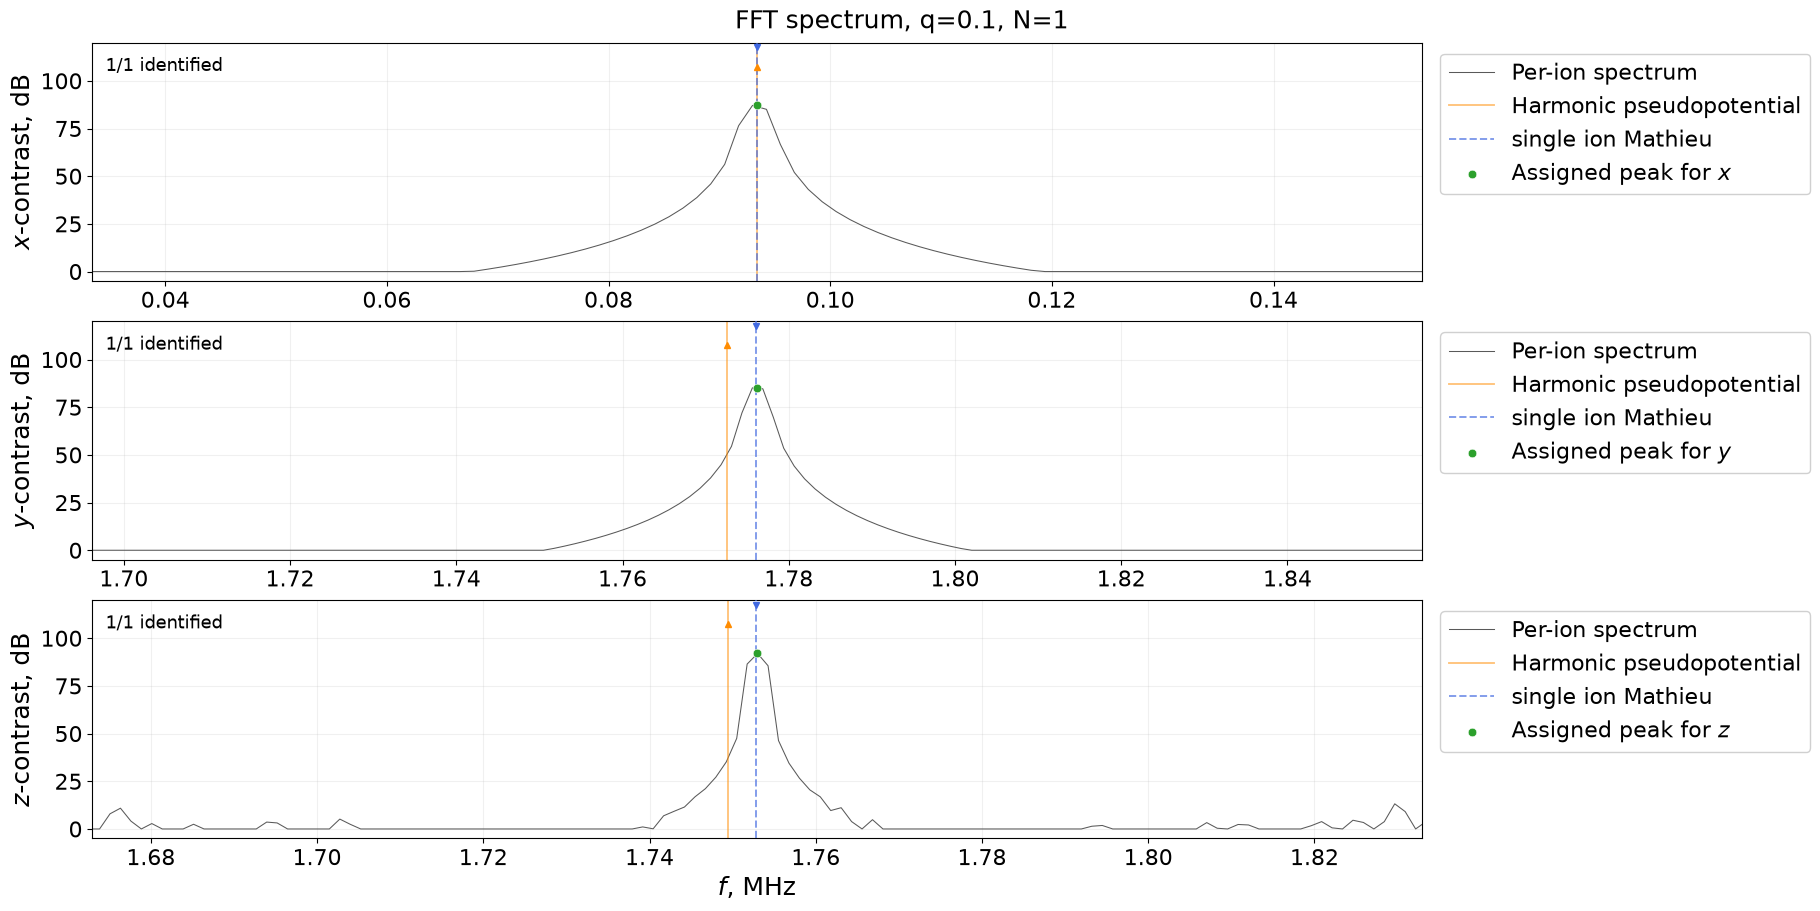

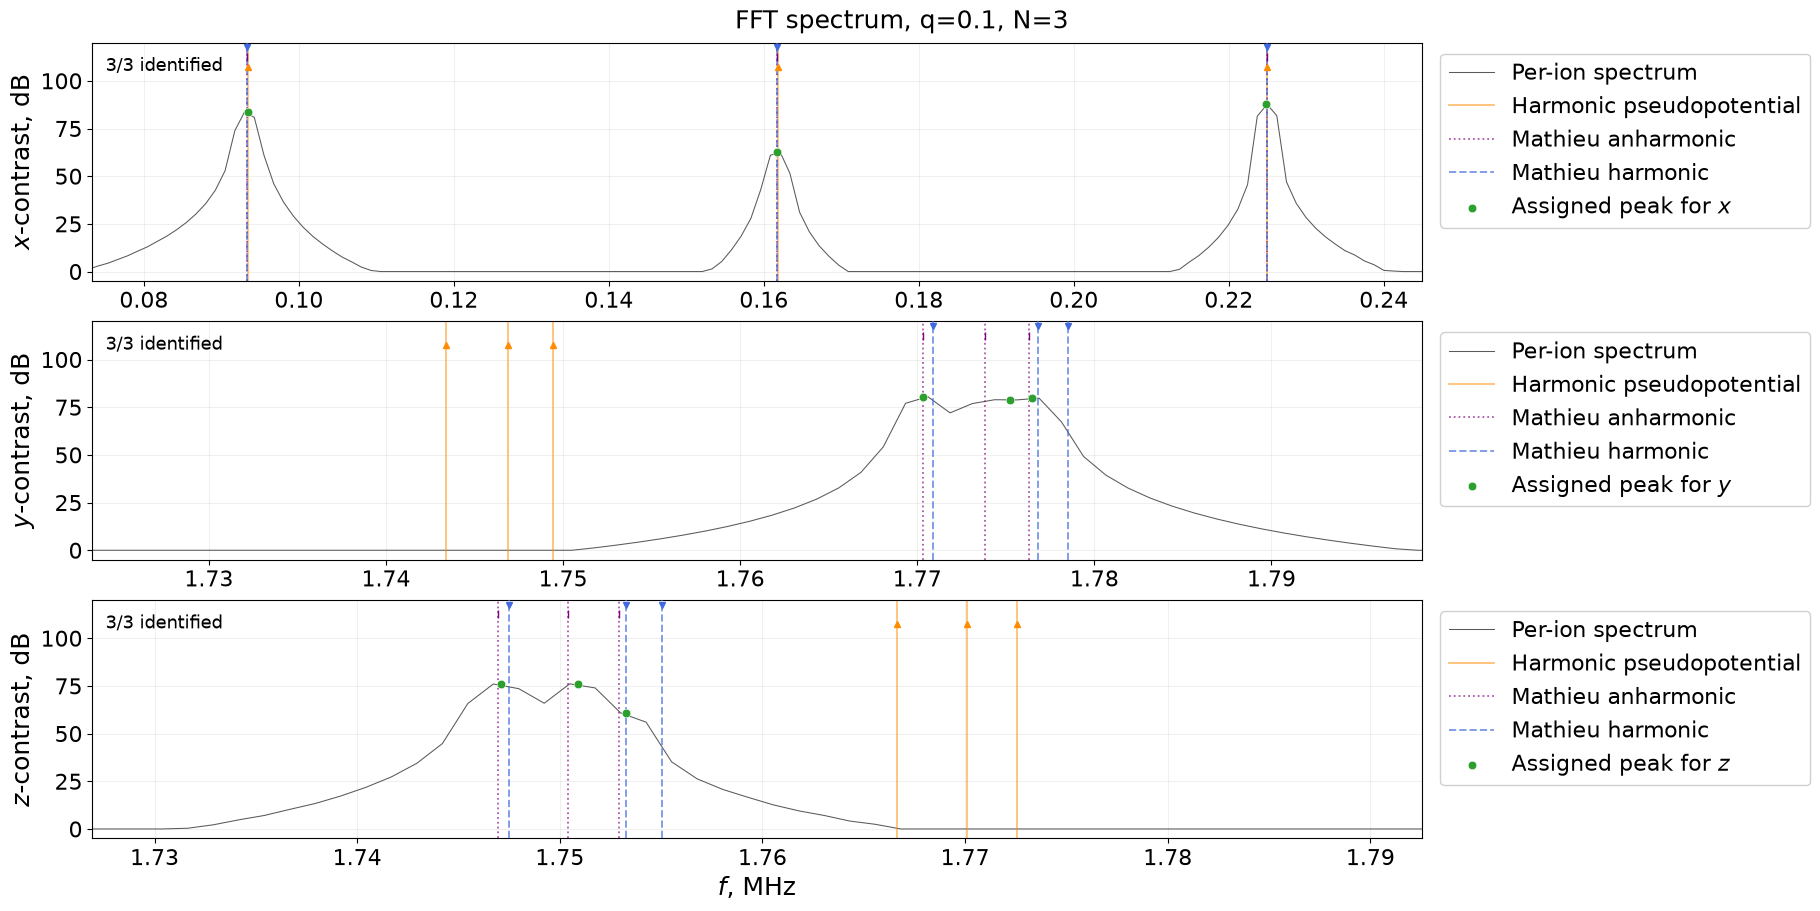

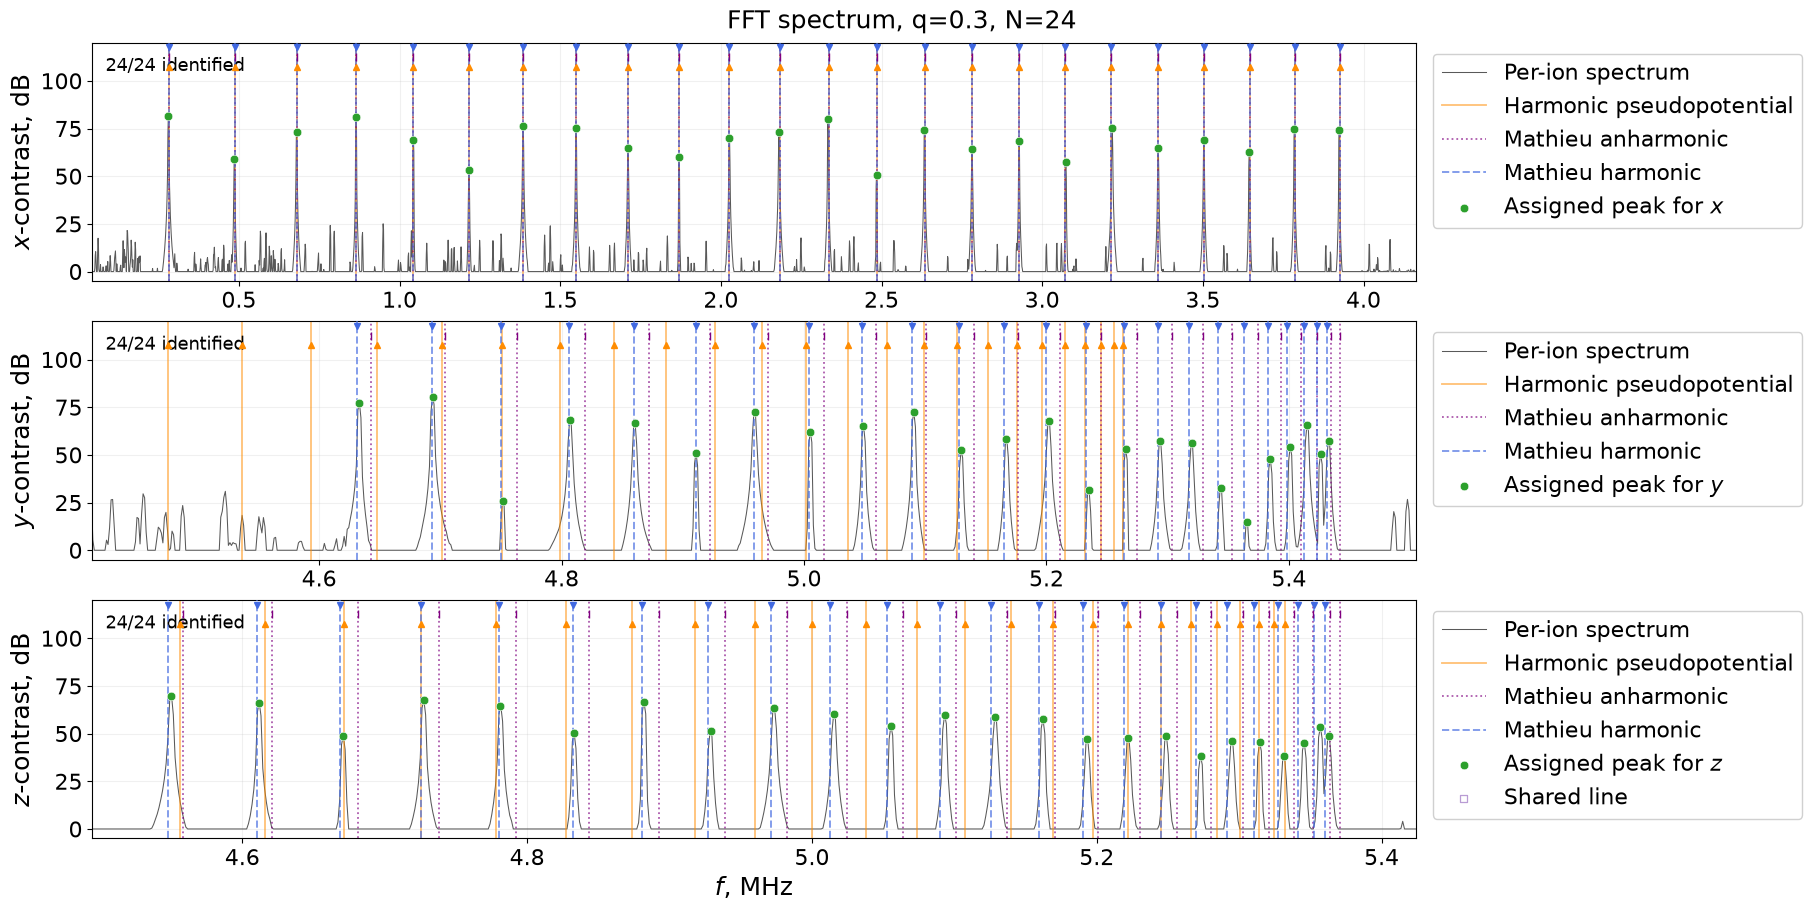

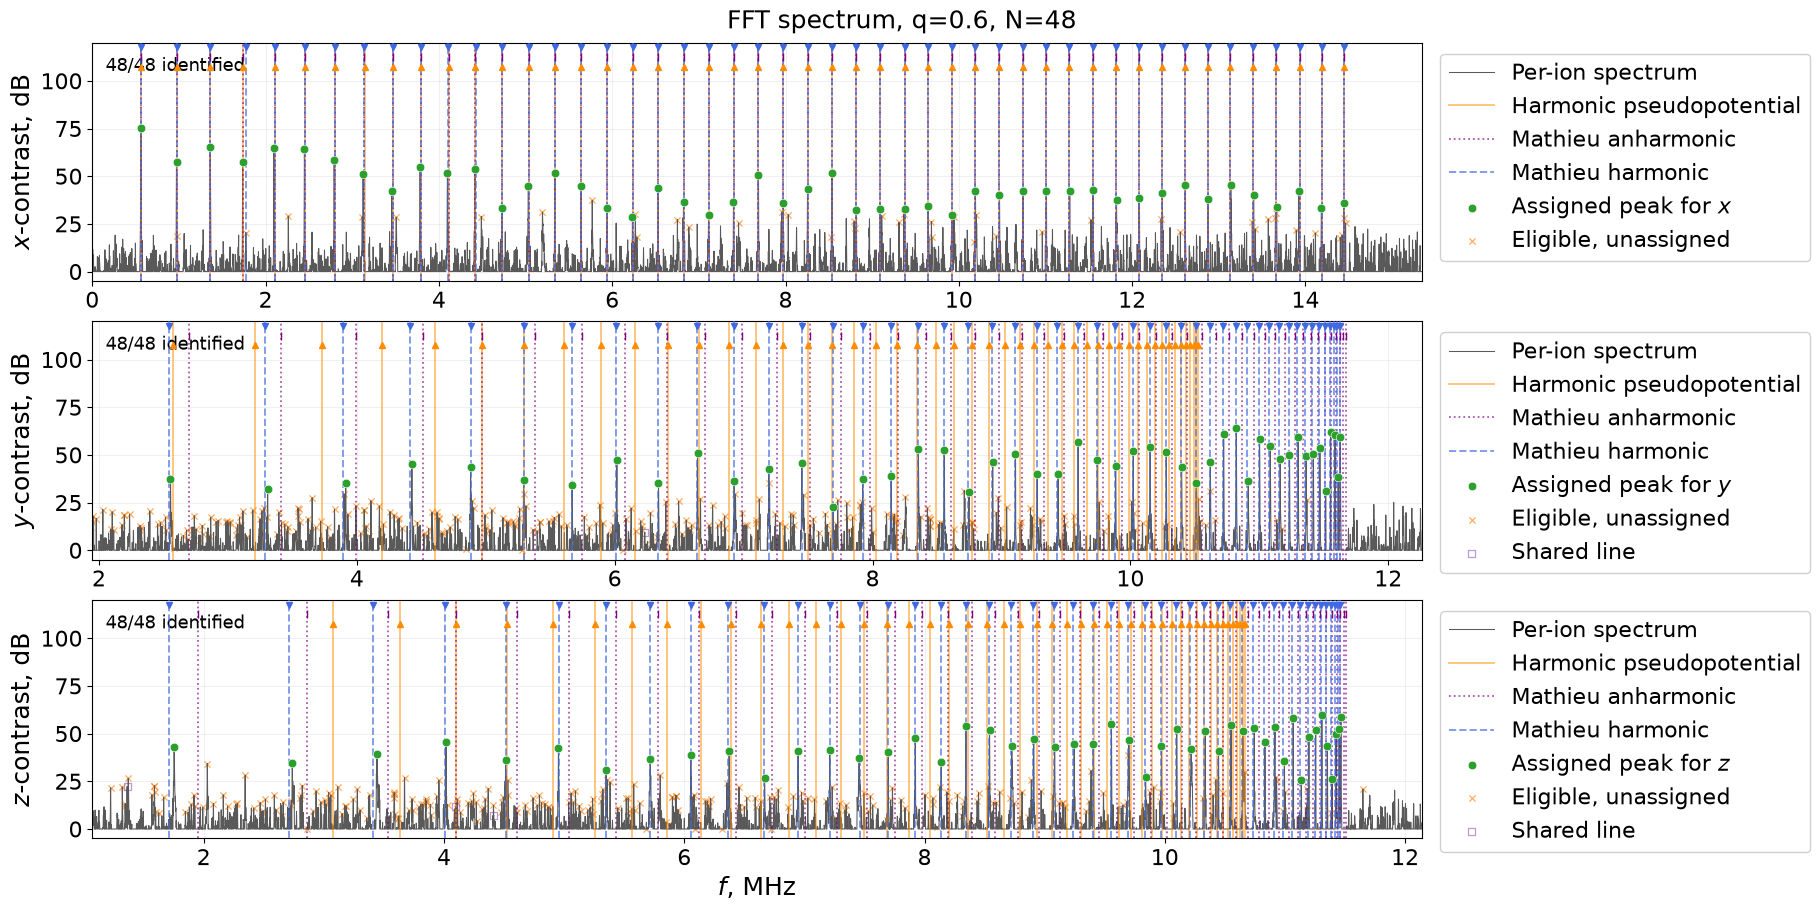

In [91]:
# Inspect selected cases, or all verified cases if desired.
PLOT_ALL = False
PLOT_CASES = [(0.1, 1), (0.1, 3), (0.3, 24), (0.6, 48)]
PREDICTION_MODEL = PEAK_SELECTION['anchor_model']  # plot guide; change independently if desired
SHOW_OTHER_MATHIEU = True
SPECTRUM_VIEW = 'contrast' 
verified_cases = selected_cases(configurations,case_pairs=VERIFY_CASES)
if PLOT_ALL: PLOT_CASES = verified_cases
for q,N in PLOT_CASES:
    if (q,N) not in verified_cases: continue
    fig,axs=plot_verification_spectra(q,N,show_harmonic=True,spectrum=SPECTRUM_VIEW,
        prediction_model=PREDICTION_MODEL,show_other_mathieu=SHOW_OTHER_MATHIEU)
    if q == 0.3 and N==24:
        fig.savefig(results_dir/'fft_trajectories_for_pub.pdf', bbox_inches="tight", dpi=300)
    plt.show()


### Finalized results

Finalized results and plots. Compares calculation accuracy of different models. Some additional analysis is provided.

The RMSE is conditional on Mathieu-assisted labeling and matched-mode coverage, not independent full-spectrum accuracy. 

The optional local-Hessian Floquet audit uses direct electrode second derivatives at saved equilibrium positions and the Coulomb Hessian. 


,q,N,source_model,axis,n_matched,n_expected,matched_rmse_khz,full_rmse_khz
0,0.1,1,analytic_harmonic,x,1,1,0.019897,0.019897
1,0.1,1,analytic_harmonic,y,1,1,3.649396,3.649396
2,0.1,1,analytic_harmonic,z,1,1,3.546232,3.546232
3,0.1,1,analytic_harmonic,all,3,3,2.937927,2.937927
4,0.1,1,analytic_single_ion_mathieu,x,1,1,0.019897,0.019897
...,...,...,...,...,...,...,...,...
763,0.6,48,md_mathieu_harmonic,all,144,144,4.548648,4.548648
764,0.6,48,md_mathieu_anharmonic,x,48,48,1.779339,1.779339
765,0.6,48,md_mathieu_anharmonic,y,48,48,54.050857,54.050857
766,0.6,48,md_mathieu_anharmonic,z,48,48,56.472533,56.472533


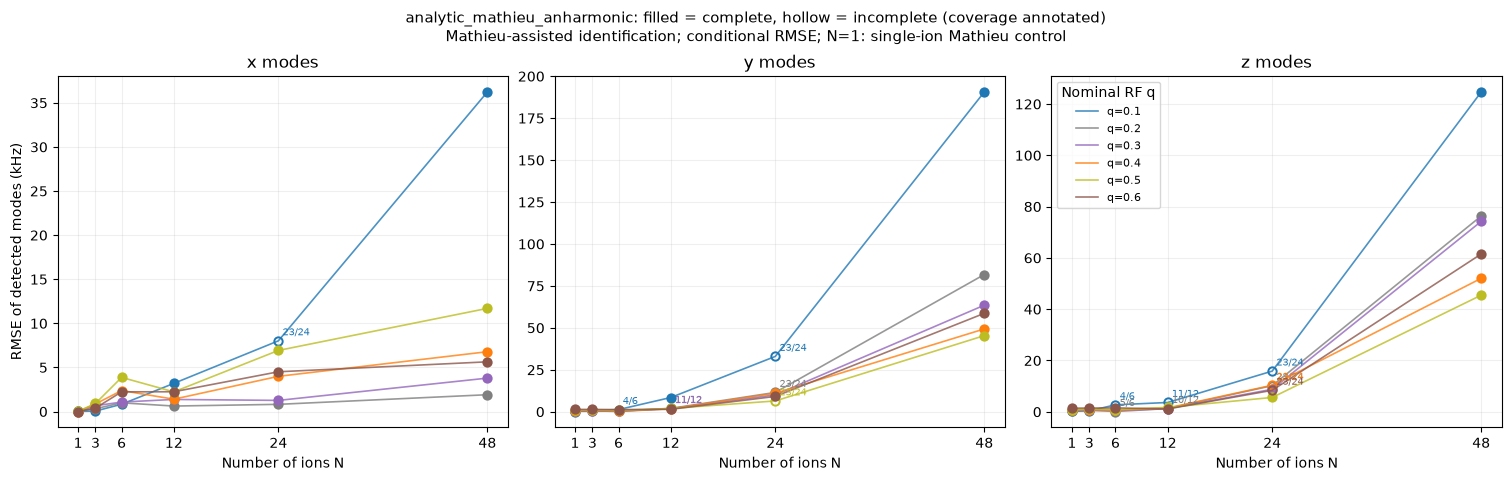

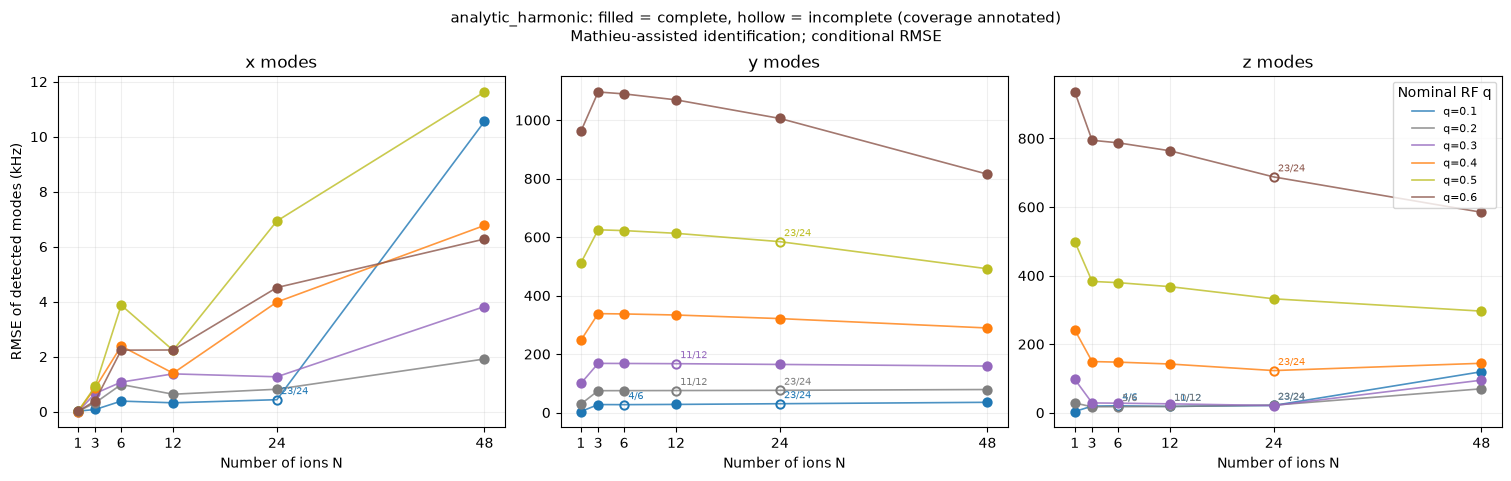

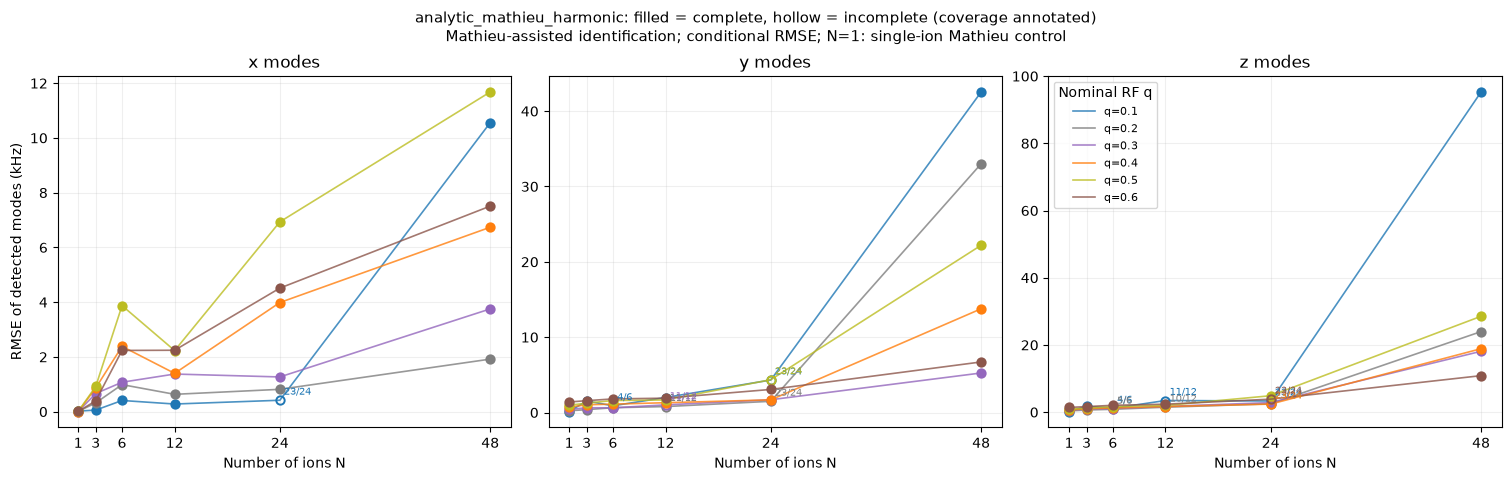

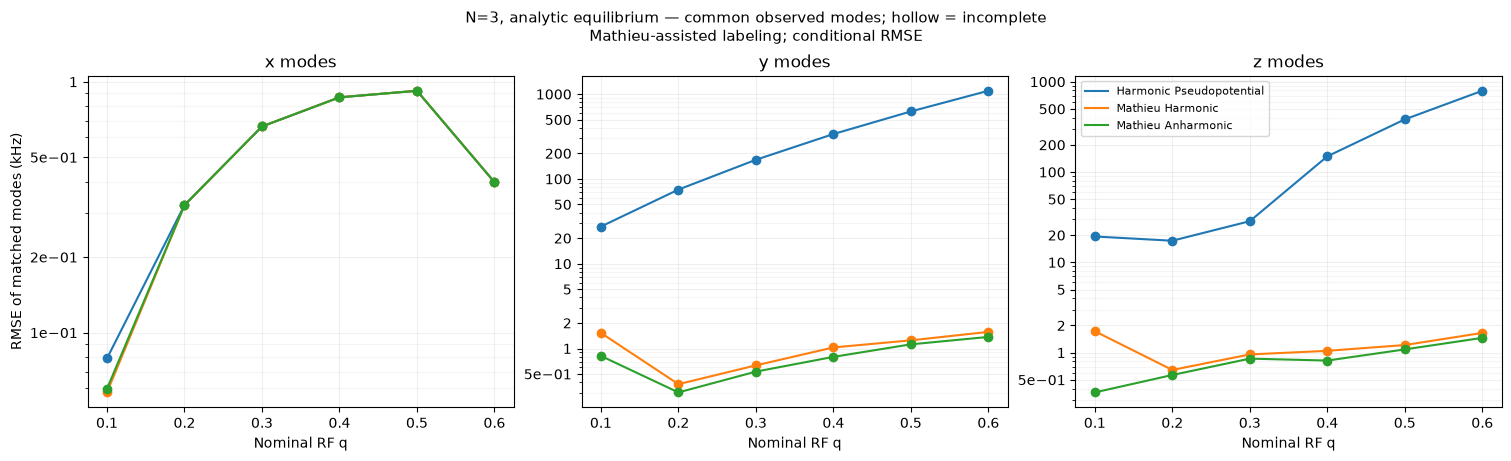

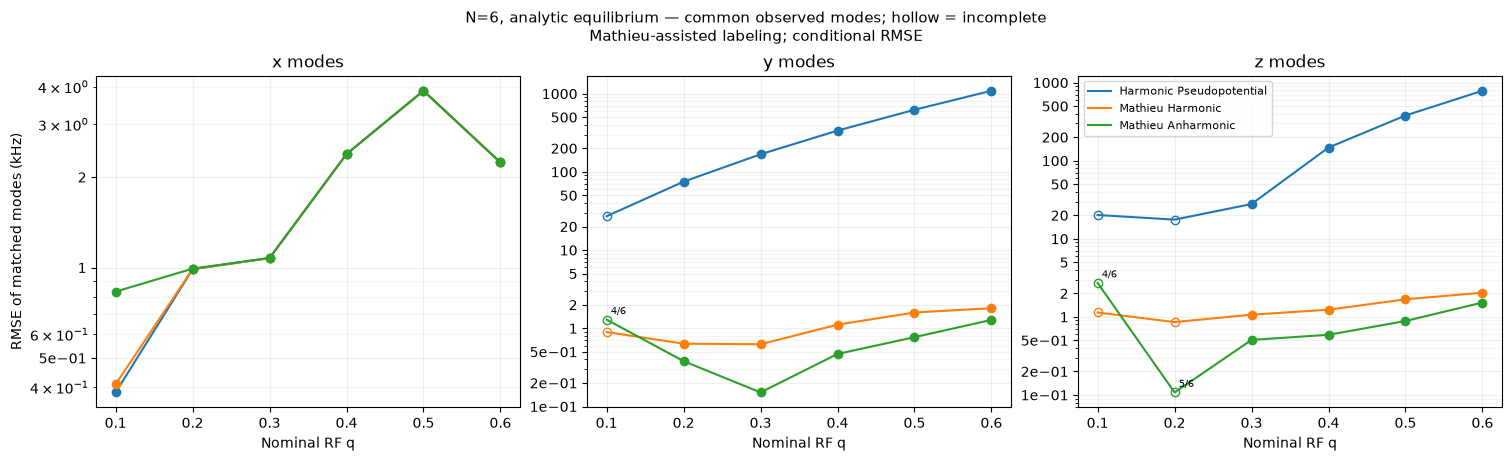

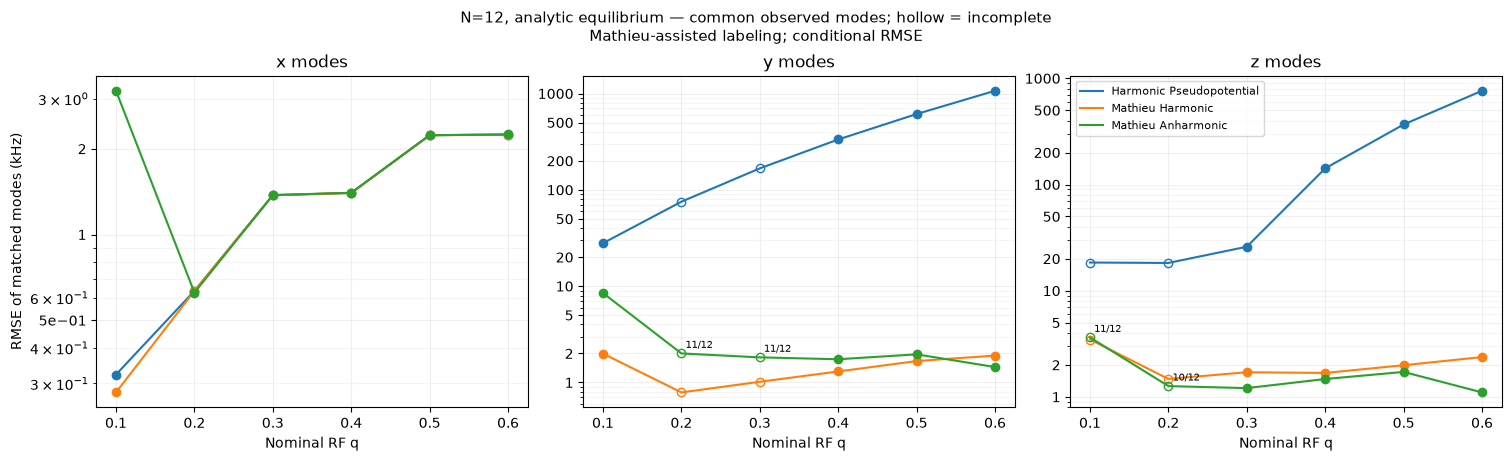

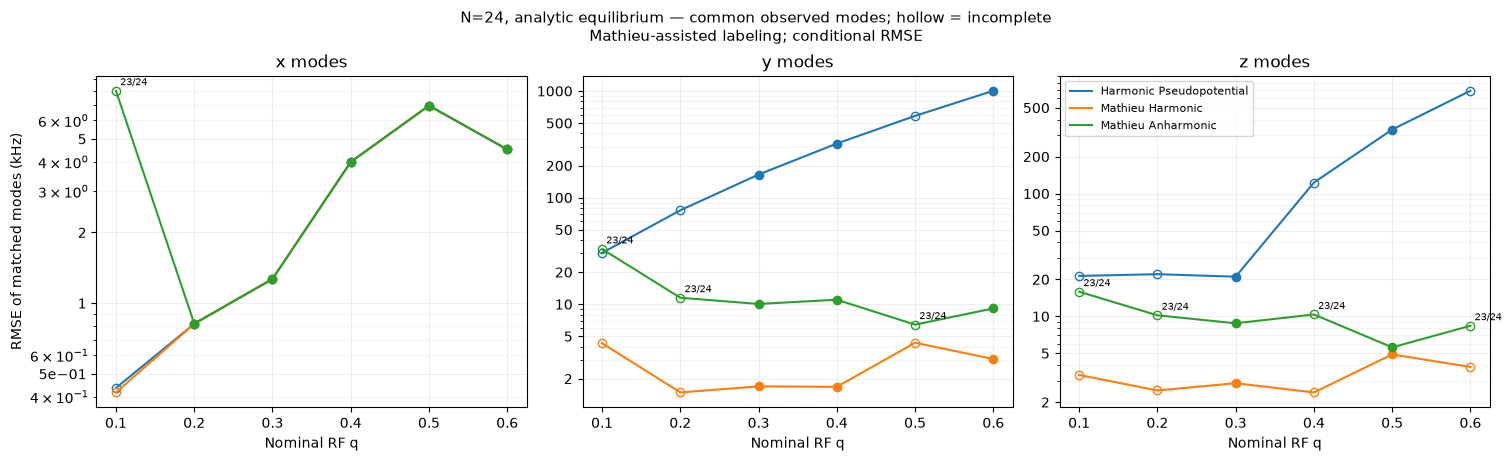

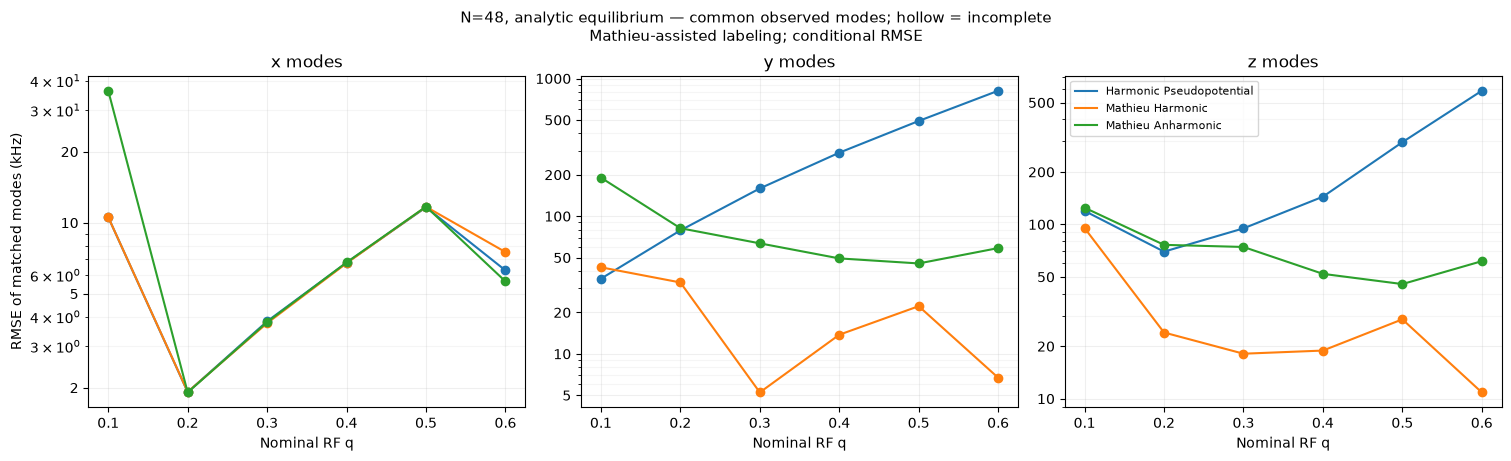

In [92]:
# Keep partial-coverage RMSE points (hollow circles, with coverage annotations).
table = verification_table(case_pairs=VERIFY_CASES)
display(table[['q','N','source_model','axis',
               'n_matched','n_expected','matched_rmse_khz','full_rmse_khz']])
for model in ('mathieu_anharmonic','harmonic','mathieu_harmonic'):
    fig, axs = plot_verification_rmse(table,source='analytic',model=model,log_y=False)
    plt.show()

# Final model comparison: use N=24 as the cleaner primary case, N=48 as stress test.
COMPARISON_ION_NUMBERS = [3,6,12,24, 48]
for N in COMPARISON_ION_NUMBERS:
    if N not in set(table.N): continue
    fig, axs = plot_model_comparison_vs_q(table,N=N,source='analytic',log_y=True)
    plt.show()

# COM audit: compare saved single-ion frequencies with COM-like crystal modes.
# com_table = com_consistency_table(case_pairs=VERIFY_CASES)
# if not com_table.empty:
#     display(com_table[(com_table.q.isin([0.1,0.3])) & (com_table.N.isin([1,3,24,48]))
#                       & (com_table.source=='analytic')].round(3))
# # Optional, fresh numerical solver calls (no simulations; can be slow for large N).
# display(audit_solver_calls(q_values=(0.1,0.6),ion_numbers=(1,3,24),compare_local_hessian=True))


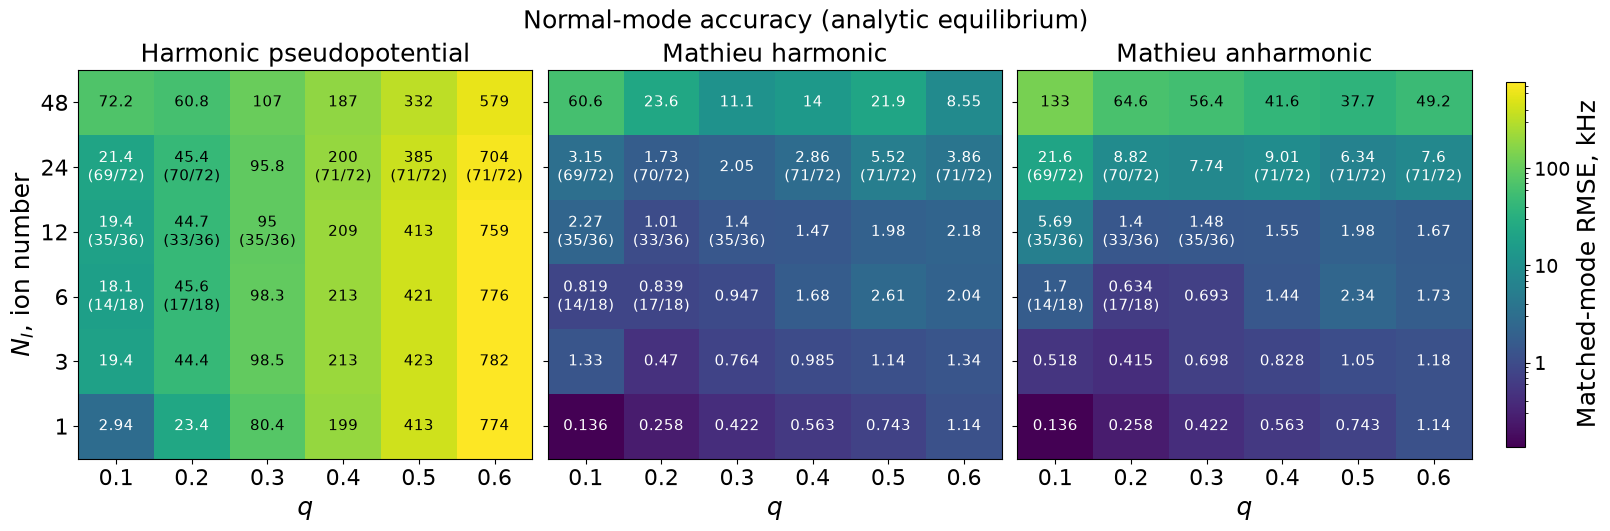

In [106]:
# Cumulative accuracy maps: one pooled RMSE over all matched x, y, z modes.
from matplotlib.colors import LogNorm
from matplotlib.ticker import LogLocator, LogFormatter


def plot_cumulative_rmse_maps(table=None, source='analytic'):
    if table is None:
        table = verification_table(case_pairs=None, save_csv=False)
    if table.empty:
        raise ValueError('No saved verification results found.')

    qs = list(configurations['qs'])
    ns = list(configurations['ion_numbers'])
    models = [('harmonic', 'Harmonic pseudopotential'),
              ('mathieu_harmonic', 'Mathieu harmonic'),
              ('mathieu_anharmonic', 'Mathieu anharmonic')]
    # The stored axis="all" RMSE pools individual residuals, not axis RMSEs.
    indexed = table.loc[table.axis == 'all'].set_index(['source_model', 'q', 'N'])
    maps, counts = [], []
    for model, _ in models:
        values = np.full((len(ns), len(qs)), np.nan)
        coverage = {}
        for i, N in enumerate(ns):
            for j, q in enumerate(qs):
                if N == 1:
                    key = 'analytic_harmonic' if model == 'harmonic' else 'analytic_single_ion_mathieu'
                else:
                    key = f'{source}_{model}'
                if (key, q, N) not in indexed.index:
                    continue
                row = indexed.loc[(key, q, N)]
                values[i, j] = row['matched_rmse_khz']
                coverage[i, j] = (int(row['n_matched']), int(row['n_expected']))
        maps.append(values)
        counts.append(coverage)

    # Share one normalization across the three panels for direct comparison.
    positive = np.concatenate([v[np.isfinite(v) & (v > 0)] for v in maps])
    if not positive.size:
        raise ValueError('No positive RMSE values available for a logarithmic color scale.')
    lo, hi = float(positive.min()), float(positive.max())
    if lo == hi:
        lo, hi = lo / 2, hi * 2
    norm = LogNorm(vmin=lo, vmax=hi)
    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('0.90')

    fig, axs = plt.subplots(1, 3, figsize=(16, 5.2),
                            sharex=True, sharey=True, constrained_layout=True)
    for ax, (model, label), values, coverage in zip(axs, models, maps, counts):
        im = ax.imshow(np.ma.masked_where(~np.isfinite(values) | (values <= 0), values),
                       origin='lower', aspect='auto', cmap=cmap, norm=norm,
                       interpolation='nearest')
        for i, N in enumerate(ns):
            for j, q in enumerate(qs):
                value = values[i, j]
                n_matched, n_expected = coverage.get((i, j), (0, 0))
                shared = '' if N == 1 and model != 'harmonic' and (i, j) in coverage else ''
                if not np.isfinite(value):
                    text, color = ('n/a', '0.25')
                elif value == 0:
                    text, color = ('0' + shared, '0.25')
                else:
                    text = f'{value:.3g}' + shared
                    r, g, b, _ = cmap(norm(value))
                    luminance = 0.2126*r + 0.7152*g + 0.0722*b
                    color = 'black' if luminance > 0.55 else 'white'
                if n_expected and n_matched < n_expected:
                    text += f'\n({n_matched}/{n_expected})'
                ax.text(j, i, text, ha='center', va='center', color=color, fontsize=11)
        ax.set_title(label, fontsize=18)
        ax.set_xlabel('$q$', fontsize=18)
        ax.set_xticks(range(len(qs)), [f'{q:g}' for q in qs], fontsize=16)
        ax.set_yticks(range(len(ns)), [str(N) for N in ns], fontsize=16)
    axs[0].set_ylabel('$N_I$, ion number', fontsize=18)
    cbar = fig.colorbar(im, ax=axs, pad=0.025, shrink=0.94)
    cbar.set_label('Matched-mode RMSE, kHz', fontsize=18)
    cbar.formatter = LogFormatter(base=10, labelOnlyBase=False,
                                 minor_thresholds=(np.inf, np.inf))
    cbar.set_ticks([1, 10, 100], labels=[1, 10, 100], fontsize=14)
    cbar.ax.yaxis.set_minor_locator(LogLocator(base=10, subs=(3, 4, 6, 7, 8, 9), numticks=100))
    fig.suptitle(f'Normal-mode accuracy ({source} equilibrium)', fontsize=18)
    return fig, axs


fig, axs = plot_cumulative_rmse_maps(source='analytic')
plt.show()
fig.savefig(results_dir / 'cumulative_mode_rmse.pdf', bbox_inches='tight')
